
# Predicting Depression History Using Machine Learning and Deep Learning

## Machine Learning Summative Project

**Dataset:** CDC Behavioral Risk Factor Surveillance System (BRFSS), 2024

**Problem Type:** Binary Classification

**Objective:** Compare traditional machine learning algorithms and deep learning models in predicting whether an adult reports having previously received a depression diagnosis.

**Approaches:**
- Traditional ML: Logistic Regression, Random Forest, Gradient Boosting
- Deep Learning: TensorFlow/Keras Neural Networks
- Evaluation: Precision, Recall, F1-score, ROC-AUC, Confusion Matrices and Learning Curves


In [ ]:

import pandas as pd
import numpy as np
import zipfile
import os

# Find the uploaded ZIP file
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)

# Inspect the contents without extracting everything
with zipfile.ZipFile("/content/" + zip_files[0]) as z:
    print("Files inside ZIP:", z.namelist())


ZIP files found: ['LLCP2024XPT.zip']
Files inside ZIP: ['LLCP2024.XPT ']


In [40]:

import shutil
import os

source = "/content/LLCP2024XPT.zip"

destination = (
    "/content/drive/MyDrive/"
    "BRFSS_Depression_Project/LLCP2024XPT.zip"
)

# Copy the original dataset to Google Drive
shutil.copy2(source, destination)

# Verify the saved file
if os.path.isfile(destination):
    size_mb = os.path.getsize(destination) / (1024 ** 2)

    print("Dataset successfully saved to Google Drive!")
    print("File:", destination)
    print(f"Size: {size_mb:.2f} MB")
else:
    print("Dataset copy failed.")


Dataset successfully saved to Google Drive!
File: /content/drive/MyDrive/BRFSS_Depression_Project/LLCP2024XPT.zip
Size: 79.16 MB


In [ ]:

import pandas as pd
import zipfile
import os

zip_path = "/content/LLCP2024XPT.zip"
extract_path = "/content/brfss_data"

# Extract the ZIP file
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Find the XPT file, including any trailing spaces
xpt_files = [
    f for f in os.listdir(extract_path)
    if f.strip().upper().endswith(".XPT")
]

print("XPT files found:", xpt_files)

# Load the dataset
file_path = os.path.join(extract_path, xpt_files[0])

df = pd.read_sas(file_path, format="xport")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


XPT files found: ['LLCP2024.XPT ']
Dataset loaded successfully!
Dataset shape: (457670, 301)


In [ ]:

# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check whether our target variable exists
print("Depression target available:", "ADDEPEV3" in df.columns)

# Examine the depression target values
if "ADDEPEV3" in df.columns:
    print(df["ADDEPEV3"].value_counts(dropna=False))


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000001',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000002',2.024000e+09,1.0,...,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
2,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000003',2.024000e+09,1.0,...,4.0,2.0,1.0,1.000000e+02,2.0,1.400000e+03,1.0,NaN,NaN,2.0
3,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000004',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000005',2.024000e+09,1.0,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0


Number of rows: 457670
Number of columns: 301
Depression target available: True
ADDEPEV3
2.0    358881
1.0     96125
7.0      2066
9.0       593
NaN         5
Name: count, dtype: int64



## 3. Target Variable Exploration

The target variable for this classification project is `ADDEPEV3`, which records whether a respondent has ever been told by a healthcare professional that they had a depressive disorder.

This is a binary classification task. We will examine the response distribution before deciding how to handle missing, refused, and uncertain responses.


In [ ]:

# Check the target variable
print("Target variable exists:", "ADDEPEV3" in df.columns)

# Display all response categories and their frequencies
if "ADDEPEV3" in df.columns:
    print("\nDepression history response distribution:")
    print(df["ADDEPEV3"].value_counts(dropna=False))

    print("\nResponse percentages:")
    print(
        df["ADDEPEV3"].value_counts(
            normalize=True,
            dropna=False
        ) * 100
    )
else:
    print("Target variable not found. Check column names.")


Target variable exists: True

Depression history response distribution:
ADDEPEV3
2.0    358881
1.0     96125
7.0      2066
9.0       593
NaN         5
Name: count, dtype: int64

Response percentages:
ADDEPEV3
2.0    78.414797
1.0    21.003125
7.0     0.451417
9.0     0.129569
NaN     0.001092
Name: proportion, dtype: float64



### Target Variable Cleaning

The original depression-history variable (`ADDEPEV3`) contains responses indicating Yes, No, Don't know, Refused, and missing values.

For binary classification, only valid Yes and No responses are retained. The target is encoded as:

- 1: Respondent reports a previous depression diagnosis.
- 0: Respondent does not report a previous depression diagnosis.

This ensures that uncertain and missing responses are not incorrectly treated as negative cases.


In [ ]:

# Create a cleaned copy of the dataset
df_clean = df[df["ADDEPEV3"].isin([1.0, 2.0])].copy()

# Encode the binary target
df_clean["Depression"] = df_clean["ADDEPEV3"].map({
    1.0: 1,
    2.0: 0
}).astype(int)

# Remove the original target to avoid leakage
df_clean.drop(columns=["ADDEPEV3"], inplace=True)

# Check the cleaned dataset
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nTarget distribution:")
print(df_clean["Depression"].value_counts())

print("\nTarget percentages:")
print(
    df_clean["Depression"].value_counts(normalize=True) * 100
)

print("\nMissing target values:")
print(df_clean["Depression"].isna().sum())


Original dataset shape: (457670, 301)
Cleaned dataset shape: (455006, 301)

Target distribution:
Depression
0    358881
1     96125
Name: count, dtype: int64

Target percentages:
Depression
0    78.873905
1    21.126095
Name: proportion, dtype: float64

Missing target values:
0



### Feature Selection and Data Understanding

The BRFSS dataset contains demographic, lifestyle, and health-related variables.

This stage examines candidate predictors to identify variables that may be useful for depression-history classification.

Feature selection will consider:
- Relevance to the research question
- Missing values and special response codes
- Potential target leakage
- Data availability and interpretability
- Ethical considerations

The final feature set will be determined before model training.


In [ ]:

# Candidate variables for initial inspection
candidate_features = [
    "_AGEG5YR",   # Age category
    "SEXVAR",     # Sex
    "EDUCA",      # Education level
    "EMPLOY1",    # Employment status
    "INCOME3",    # Household income category
    "GENHLTH",    # General health
    "PHYSHLTH",   # Poor physical health days
    "MENTHLTH",   # Poor mental health days
    "EXERANY2",   # Physical activity
    "SLEPTIM1",   # Sleep duration
    "MARITAL",    # Marital status
    "_BMI5",      # Body Mass Index (scaled)
    "SMOKE100"    # Lifetime cigarette use
]

# Check availability
available_features = [
    col for col in candidate_features
    if col in df_clean.columns
]

missing_features = [
    col for col in candidate_features
    if col not in df_clean.columns
]

print("Available features:", len(available_features))
print(available_features)

print("\nUnavailable features:")
print(missing_features)

# Inspect missing values and distinct values
feature_summary = pd.DataFrame({
    "Data Type": df_clean[available_features].dtypes.astype(str),
    "Missing Values": df_clean[available_features].isna().sum(),
    "Missing %": (
        df_clean[available_features].isna().mean() * 100
    ).round(2),
    "Unique Values": df_clean[available_features].nunique()
})

display(feature_summary)


Available features: 12
['_AGEG5YR', 'SEXVAR', 'EDUCA', 'EMPLOY1', 'INCOME3', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'EXERANY2', 'MARITAL', '_BMI5', 'SMOKE100']

Unavailable features:
['SLEPTIM1']


,Data Type,Missing Values,Missing %,Unique Values
_AGEG5YR,float64,0,0.00,14
SEXVAR,float64,0,0.00,2
EDUCA,float64,4,0.00,7
EMPLOY1,float64,3269,0.72,9
INCOME3,float64,9189,2.02,13
GENHLTH,float64,3,0.00,7
PHYSHLTH,float64,3,0.00,33
MENTHLTH,float64,1,0.00,33
EXERANY2,float64,1,0.00,4
MARITAL,float64,6,0.00,7



### Feature Values and Missing Data Codes

The BRFSS dataset contains categorical and numerical variables with special response codes.

This analysis examines the frequency distribution of candidate predictors and searches for available sleep-related variables.

The results will guide subsequent data cleaning, feature selection, and preprocessing decisions.


In [ ]:

# Find possible sleep-related columns
sleep_columns = [
    col for col in df_clean.columns
    if "SLEEP" in col.upper()
    or "SLEPT" in col.upper()
]

print("Sleep-related columns:")
print(sleep_columns)

# Inspect unique values and their frequencies
for col in available_features:
    print("\n" + "=" * 45)
    print("Feature:", col)
    print("=" * 45)

    print(
        df_clean[col]
        .value_counts(dropna=False)
        .head(20)
    )


Sleep-related columns:
[]

Feature: _AGEG5YR
_AGEG5YR
10.0    47498
11.0    44576
9.0     43201
13.0    41524
12.0    36619
8.0     34769
7.0     31570
5.0     30735
1.0     29378
6.0     28841
4.0     28641
3.0     26077
2.0     23525
14.0     8052
Name: count, dtype: int64

Feature: SEXVAR
SEXVAR
2.0    238926
1.0    216080
Name: count, dtype: int64

Feature: EDUCA
EDUCA
6.0    190745
5.0    120010
4.0    115107
3.0     17071
2.0      9130
9.0      2221
1.0       718
NaN         4
Name: count, dtype: int64

Feature: EMPLOY1
EMPLOY1
1.0    185479
7.0    146228
2.0     38984
8.0     27487
5.0     17730
6.0     11363
4.0     10703
3.0      8856
9.0      4907
NaN      3269
Name: count, dtype: int64

Feature: INCOME3
INCOME3
7.0     60462
9.0     55618
8.0     51551
6.0     49428
5.0     41491
99.0    40537
77.0    36572
11.0    29625
10.0    26614
4.0     19712
3.0     13571
2.0     10461
1.0     10175
NaN      9189
Name: count, dtype: int64

Feature: GENHLTH
GENHLTH
3.0    155275
2.0   


### Cleaning Predictor Variables

The BRFSS dataset uses special numeric codes to represent missing, unknown, refused, and zero responses.

These codes must be handled before model training to avoid introducing misleading numerical relationships.

This stage:
- Converts special missing-response codes into NaN.
- Converts 88 into zero for physical and mental health days.
- Converts BMI into its original measurement scale.
- Preserves categorical variables for later encoding.
- Avoids dropping records unnecessarily.

Missing-value imputation will be performed later using training-data-only preprocessing pipelines to prevent data leakage.


In [ ]:

# Create a separate DataFrame for selected features
df_model = df_clean[available_features + ["Depression"]].copy()

# Special response codes for categorical variables
missing_codes = {
    "_AGEG5YR": [14],
    "SEXVAR": [],
    "EDUCA": [9],
    "EMPLOY1": [9],
    "INCOME3": [77, 99],
    "GENHLTH": [7, 9],
    "EXERANY2": [7, 9],
    "MARITAL": [9],
    "SMOKE100": [7, 9]
}

# Replace invalid response codes with NaN
for col, codes in missing_codes.items():
    df_model[col] = df_model[col].replace(codes, np.nan)

# Clean physical and mental health days
for col in ["PHYSHLTH", "MENTHLTH"]:
    df_model[col] = df_model[col].replace({
        88: 0,
        77: np.nan,
        99: np.nan
    })

    # Only 0–30 days are valid
    df_model.loc[
        ~df_model[col].between(0, 30),
        col
    ] = np.nan

# Convert BMI to original scale
df_model["_BMI5"] = df_model["_BMI5"] / 100

# Check results
print("Cleaned modeling dataset shape:", df_model.shape)

print("\nMissing values after recoding:")
print(
    df_model.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nTarget distribution:")
print(df_model["Depression"].value_counts())


Cleaned modeling dataset shape: (455006, 13)

Missing values after recoding:
INCOME3       86298
_BMI5         42498
SMOKE100      31109
PHYSHLTH      10798
EMPLOY1        8176
_AGEG5YR       8052
MENTHLTH       7738
MARITAL        4045
EDUCA          2225
GENHLTH        1228
EXERANY2       1216
SEXVAR            0
Depression        0
dtype: int64

Target distribution:
Depression
0    358881
1     96125
Name: count, dtype: int64



## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is conducted to understand the characteristics of the cleaned BRFSS 2024 dataset.

The analysis examines:
- Distribution of depression-history classes
- Demographic characteristics
- Physical and mental health indicators
- Relationships between selected predictors and depression history
- Missing data patterns

The findings will inform feature engineering, model selection, and evaluation strategies.

All initial descriptive results are based on unweighted survey responses. Survey-weighted estimates will be considered separately.


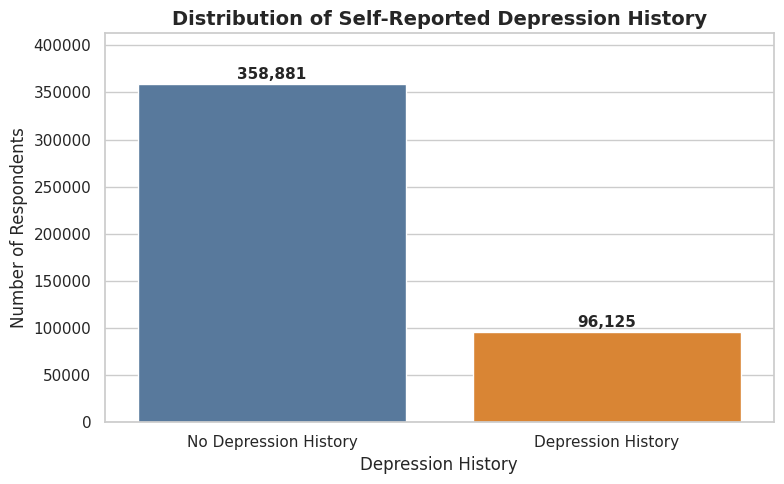

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visualization style
sns.set_theme(style="whitegrid")

# Calculate class frequencies
class_counts = (
    df_model["Depression"]
    .value_counts()
    .sort_index()
)

# Create the visualization
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["No Depression History", "Depression History"],
    y=class_counts.values,
    palette=["#4C78A8", "#F58518"],
    hue=["No Depression History", "Depression History"],
    legend=False
)

# Add count labels
for i, count in enumerate(class_counts.values):
    ax.text(
        i,
        count + 5000,
        f"{count:,}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Distribution of Self-Reported Depression History",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Depression History")
plt.ylabel("Number of Respondents")
plt.ylim(0, max(class_counts.values) * 1.15)

plt.tight_layout()
plt.show()



### Interpretation: Depression History Distribution

The cleaned dataset contains 455,006 valid responses, including 358,881 respondents (78.87%) who reported no previous depression diagnosis and 96,125 respondents (21.13%) who reported a depression history.

The distribution indicates class imbalance, with the negative class representing approximately four-fifths of observations. Consequently, accuracy alone may provide an incomplete assessment of classification performance.

Precision, recall, F1-score, and ROC-AUC will be used alongside accuracy to assess model performance. These percentages describe the unweighted sample and should not be interpreted as population prevalence estimates.



### **Depression History by Age Group**

This analysis examines the relationship between respondents' age groups and their self-reported depression history.

The proportion of respondents reporting a previous depression diagnosis is calculated for each age group to identify potential differences across age categories.


,_AGEG5YR,mean,count,Depression_Percentage
0,1.0,0.249575,29378,24.957451
1,2.0,0.272561,23525,27.256111
2,3.0,0.272194,26077,27.219389
3,4.0,0.261408,28641,26.140847
4,5.0,0.254498,30735,25.449813
5,6.0,0.248258,28841,24.825769
6,7.0,0.241083,31570,24.108331
7,8.0,0.234145,34769,23.414536
8,9.0,0.219509,43201,21.950881
9,10.0,0.187882,47498,18.788160


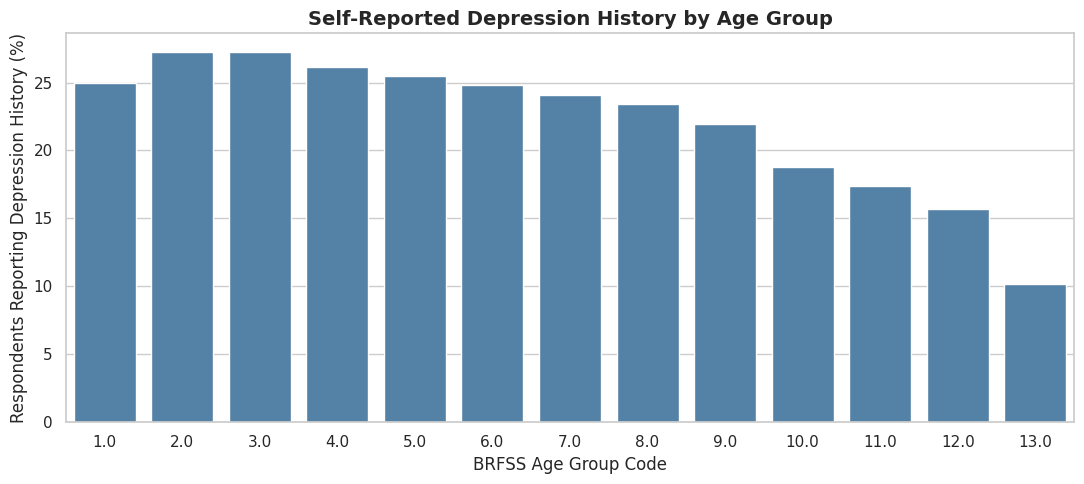

In [ ]:

# Calculate depression history percentage by age group
age_depression = (
    df_model.groupby("_AGEG5YR")["Depression"]
    .agg(["mean", "count"])
    .reset_index()
)

# Convert proportions to percentages
age_depression["Depression_Percentage"] = (
    age_depression["mean"] * 100
)

# Remove missing age categories from visualization
age_depression = age_depression.dropna(
    subset=["_AGEG5YR"]
)

# Display results
display(age_depression)

# Plot depression history by age group
plt.figure(figsize=(11, 5))

sns.barplot(
    data=age_depression,
    x="_AGEG5YR",
    y="Depression_Percentage",
    color="steelblue"
)

plt.title(
    "Self-Reported Depression History by Age Group",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("BRFSS Age Group Code")
plt.ylabel("Respondents Reporting Depression History (%)")

plt.tight_layout()
plt.show()



### Interpretation

The analysis shows differences in self-reported depression history across age groups. Respondents aged 25–29 recorded the highest percentage (27.26%), while respondents aged 80 and above recorded the lowest (10.15%).

After the younger age groups, the percentage generally decreases as age increases. This suggests that age may be a useful predictor of reported depression history.

However, these findings are descriptive and do not establish a causal relationship. The results are also unweighted and may be influenced by differences in diagnosis and reporting.



### **Depression History by Sex**

This analysis compares the proportion of male and female respondents who reported having previously received a depression diagnosis.

Percentages are calculated within each group to account for differences in the number of respondents.


,SEXVAR,mean,count,Sex,Depression_Percentage
0,1.0,0.153688,216080,Male,15.368845
1,2.0,0.263328,238926,Female,26.332839


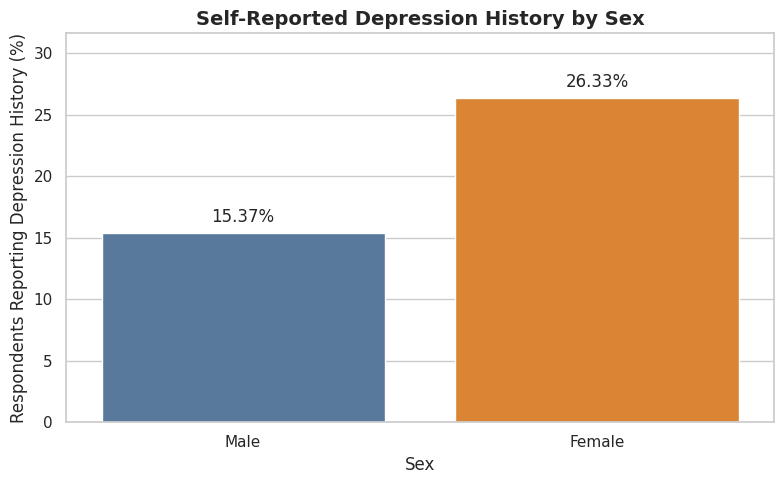

In [ ]:

# Create readable labels for sex categories
sex_labels = {
    1.0: "Male",
    2.0: "Female"
}

# Calculate depression percentage by sex
sex_depression = (
    df_model.groupby("SEXVAR")["Depression"]
    .agg(["mean", "count"])
    .reset_index()
)

sex_depression["Sex"] = sex_depression["SEXVAR"].map(sex_labels)

sex_depression["Depression_Percentage"] = (
    sex_depression["mean"] * 100
)

# Display the results
display(sex_depression)

# Visualize depression history by sex
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=sex_depression,
    x="Sex",
    y="Depression_Percentage",
    hue="Sex",
    palette=["#4C78A8", "#F58518"],
    legend=False
)

# Add percentage labels above bars
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title(
    "Self-Reported Depression History by Sex",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sex")
plt.ylabel("Respondents Reporting Depression History (%)")
plt.ylim(0, sex_depression["Depression_Percentage"].max() * 1.2)

plt.tight_layout()
plt.show()



### Interpretation

Female respondents had a higher percentage of self-reported depression history (26.33%) compared with male respondents (15.37%).

The difference of approximately 10.96 percentage points suggests an association between sex and reported depression history.

However, the findings do not establish causation and may reflect differences in diagnosis, healthcare access, or reporting behavior.



### **Depression History and Poor Mental Health Days**

This analysis examines the association between the number of self-reported poor mental health days in the past 30 days and depression history.

Respondents are grouped into categories based on the number of poor mental health days to compare the percentage reporting a previous depression diagnosis.


,Mental_Health_Group,mean,count,Depression_Percentage
0,0 days,0.080938,269170,8.093770
1,1–5 days,0.262418,85760,26.241838
2,6–14 days,0.431985,33478,43.198518
3,15–30 days,0.599490,58860,59.949032


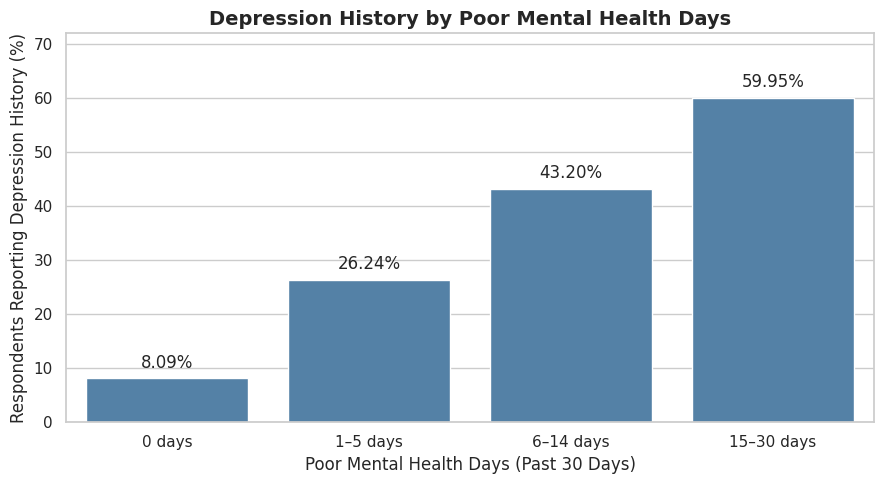

In [ ]:

# Create mental health day categories for EDA
eda_mental = df_model[
    ["MENTHLTH", "Depression"]
].copy()

# Group respondents by poor mental health days
eda_mental["Mental_Health_Group"] = pd.cut(
    eda_mental["MENTHLTH"],
    bins=[-1, 0, 5, 14, 30],
    labels=[
        "0 days",
        "1–5 days",
        "6–14 days",
        "15–30 days"
    ]
)

# Calculate depression history percentage
mental_summary = (
    eda_mental.groupby(
        "Mental_Health_Group",
        observed=True
    )["Depression"]
    .agg(["mean", "count"])
    .reset_index()
)

mental_summary["Depression_Percentage"] = (
    mental_summary["mean"] * 100
)

display(mental_summary)

# Plot results
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=mental_summary,
    x="Mental_Health_Group",
    y="Depression_Percentage",
    color="steelblue"
)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title(
    "Depression History by Poor Mental Health Days",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Poor Mental Health Days (Past 30 Days)")
plt.ylabel("Respondents Reporting Depression History (%)")

plt.ylim(
    0,
    mental_summary["Depression_Percentage"].max() * 1.2
)

plt.tight_layout()
plt.show()



### Interpretation

The results show a positive association between poor mental health days and self-reported depression history.

Only 8.09% of respondents reporting zero poor mental health days had a depression history, compared with 59.95% of respondents reporting 15–30 poor mental health days.

This suggests that recent mental health status may be an informative predictor of previously diagnosed depression. However, the analysis is descriptive and does not establish causation.



### **Depression History and Physical Health**

This analysis investigates the relationship between poor physical health days and self-reported depression history.

Respondents are grouped according to the number of days they experienced poor physical health during the past 30 days. Depression-history percentages are then compared across the groups.


,Physical_Health_Group,mean,count,Depression_Percentage
0,0 days,0.138832,266494,13.883239
1,1–5 days,0.263909,87962,26.390942
2,6–14 days,0.329529,31108,32.952938
3,15–30 days,0.395880,58644,39.588023


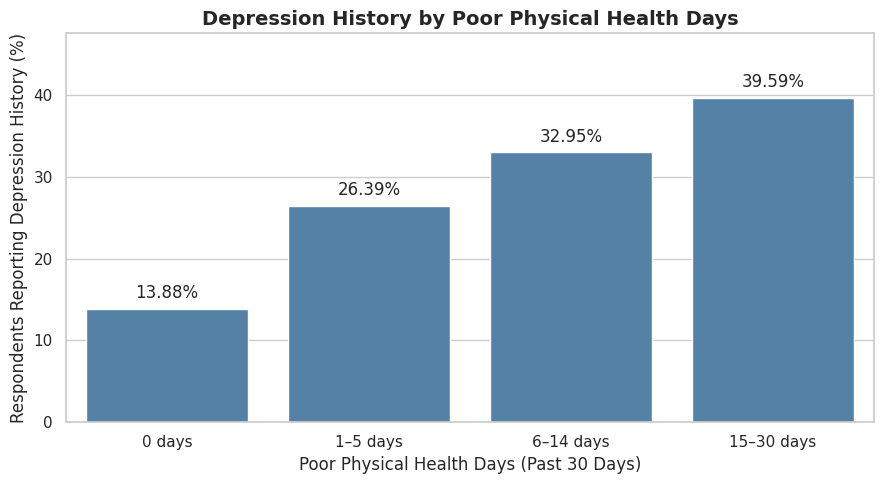

In [ ]:

# Create physical health categories for EDA
eda_physical = df_model[
    ["PHYSHLTH", "Depression"]
].copy()

# Group physical health days
eda_physical["Physical_Health_Group"] = pd.cut(
    eda_physical["PHYSHLTH"],
    bins=[-1, 0, 5, 14, 30],
    labels=[
        "0 days",
        "1–5 days",
        "6–14 days",
        "15–30 days"
    ]
)

# Calculate depression history percentages
physical_summary = (
    eda_physical.groupby(
        "Physical_Health_Group",
        observed=True
    )["Depression"]
    .agg(["mean", "count"])
    .reset_index()
)

physical_summary["Depression_Percentage"] = (
    physical_summary["mean"] * 100
)

display(physical_summary)

# Create visualization
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=physical_summary,
    x="Physical_Health_Group",
    y="Depression_Percentage",
    color="steelblue"
)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title(
    "Depression History by Poor Physical Health Days",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Poor Physical Health Days (Past 30 Days)")
plt.ylabel("Respondents Reporting Depression History (%)")

plt.ylim(
    0,
    physical_summary["Depression_Percentage"].max() * 1.2
)

plt.tight_layout()
plt.show()



### Interpretation

The results indicate an association between poor physical health days and self-reported depression history.

Among respondents reporting no poor physical health days, 13.88% reported a previous depression diagnosis. This percentage increased to 39.59% among respondents reporting 15–30 days of poor physical health.

These findings suggest that physical health may provide useful predictive information. However, the relationship is descriptive and does not establish causation.



###  **Missing Data Analysis**

This analysis examines the proportion of missing values across the selected predictor variables after recoding invalid survey responses.

Understanding missing data patterns is important for selecting appropriate imputation methods and minimizing information loss during preprocessing.


,Missing Percentage
INCOME3,18.97
_BMI5,9.34
SMOKE100,6.84
PHYSHLTH,2.37
EMPLOY1,1.80
_AGEG5YR,1.77
MENTHLTH,1.70
MARITAL,0.89
EDUCA,0.49
GENHLTH,0.27


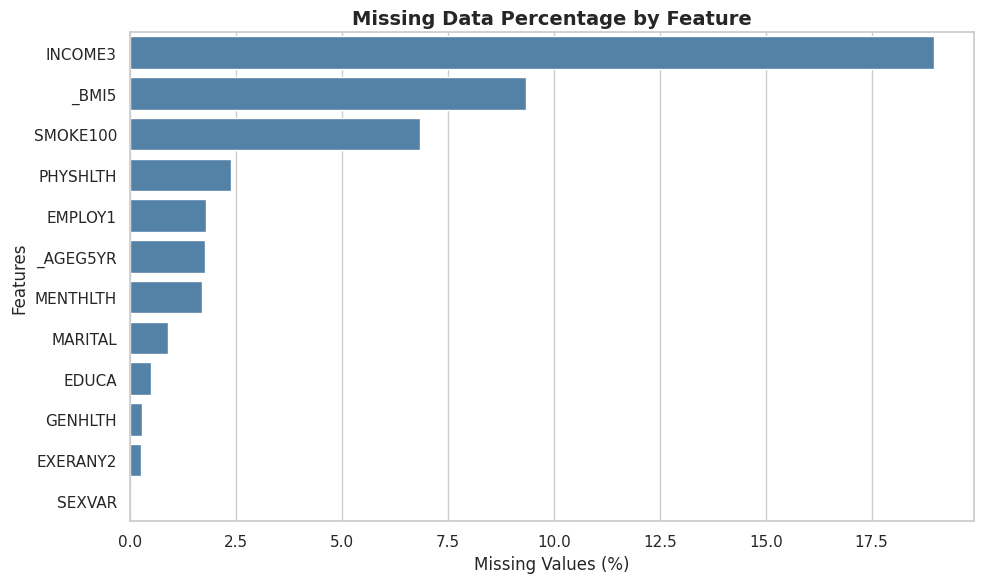

In [ ]:

# Calculate missing percentages
missing_percentage = (
    df_model.drop(columns=["Depression"])
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display missing percentages
display(
    missing_percentage
    .round(2)
    .to_frame(name="Missing Percentage")
)

# Plot missing data
plt.figure(figsize=(10, 6))

sns.barplot(
    x=missing_percentage.values,
    y=missing_percentage.index,
    color="steelblue"
)

plt.title(
    "Missing Data Percentage by Feature",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()



### Interpretation

The missing-data analysis identified household income as the feature with the highest proportion of missing values (18.97%), followed by BMI (9.34%) and smoking history (6.84%).

Most remaining predictors had relatively low missingness. Rather than removing incomplete observations, the modeling pipeline will use appropriate imputation methods fitted on training data only.

This approach preserves the available observations while reducing the risk of data leakage.



## **Data Preparation and Feature Engineering**

The dataset is divided into training (70%), validation (15%), and testing (15%) subsets using stratified sampling.

Stratification preserves the approximate distribution of depression-history classes across the subsets.

The test set is reserved for final model evaluation to minimize information leakage and provide a more reliable estimate of generalization performance.


In [ ]:

from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df_model.drop(columns=["Depression"])
y = df_model["Depression"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))


Training set: (318504, 12)
Validation set: (68251, 12)
Testing set: (68251, 12)

Training target distribution:
Depression
0    0.7887
1    0.2113
Name: proportion, dtype: float64

Validation target distribution:
Depression
0    0.7887
1    0.2113
Name: proportion, dtype: float64

Testing target distribution:
Depression
0    0.7887
1    0.2113
Name: proportion, dtype: float64



### **Data Preprocessing Pipeline**

Separate preprocessing pipelines are constructed for categorical and numerical predictors.

Categorical variables undergo most-frequent imputation followed by one-hot encoding. Numerical variables undergo median imputation and standardization.

All preprocessing transformations are fitted exclusively on the training dataset to prevent information leakage into validation and test data.


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Define categorical features
categorical_features = [
    "_AGEG5YR",
    "SEXVAR",
    "EDUCA",
    "EMPLOY1",
    "INCOME3",
    "GENHLTH",
    "EXERANY2",
    "MARITAL",
    "SMOKE100"
]

# Define numerical features
numerical_features = [
    "PHYSHLTH",
    "MENTHLTH",
    "_BMI5"
]

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_features),
        ("num", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Display transformed shapes
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# Check for remaining missing values
import numpy as np

print("\nMissing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in validation:",
      np.isnan(X_val_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())

# Check total number of transformed features
print("\nTotal transformed features:",
      X_train_processed.shape[1])


Processed training shape: (318504, 58)
Processed validation shape: (68251, 58)
Processed testing shape: (68251, 58)

Missing values in training: 0
Missing values in validation: 0
Missing values in testing: 0

Total transformed features: 58



## Traditional Machine Learning Models
### Logistic Regression Baseline

Logistic Regression is used as the first baseline classifier for predicting self-reported depression history.

The model estimates the probability of belonging to the positive class (reported depression history) based on the selected demographic, lifestyle, and health-related predictors.

Performance is evaluated on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC.


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import time

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver="lbfgs"
)

# Train the model
start_time = time.time()

lr_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

# Make validation predictions
y_val_pred_lr = lr_model.predict(X_val_processed)

# Predict probabilities for ROC-AUC
y_val_prob_lr = lr_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_val_pred_lr),
    "Precision": precision_score(
        y_val, y_val_pred_lr, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_lr, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_lr, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_val_prob_lr
    ),
    "Training Time (s)": training_time
}

# Display results
print("Logistic Regression Validation Results")
print("-" * 45)

for metric, value in lr_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr))


Logistic Regression Validation Results
---------------------------------------------
Model: Logistic Regression
Accuracy: 0.8212
Precision: 0.6565
Recall: 0.3219
F1-score: 0.4320
ROC-AUC: 0.7962
Training Time (s): 5.0680

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89     53832
           1       0.66      0.32      0.43     14419

    accuracy                           0.82     68251
   macro avg       0.75      0.64      0.66     68251
weighted avg       0.80      0.82      0.80     68251




### **Logistic Regression Confusion Matrix**
The confusion matrix is used to examine correct and incorrect predictions made by the baseline Logistic Regression classifier.

Particular attention is given to false negatives, representing respondents with reported depression history who were incorrectly classified as having no depression history.


Logistic Regression Confusion Matrix:
[[51403  2429]
 [ 9777  4642]]


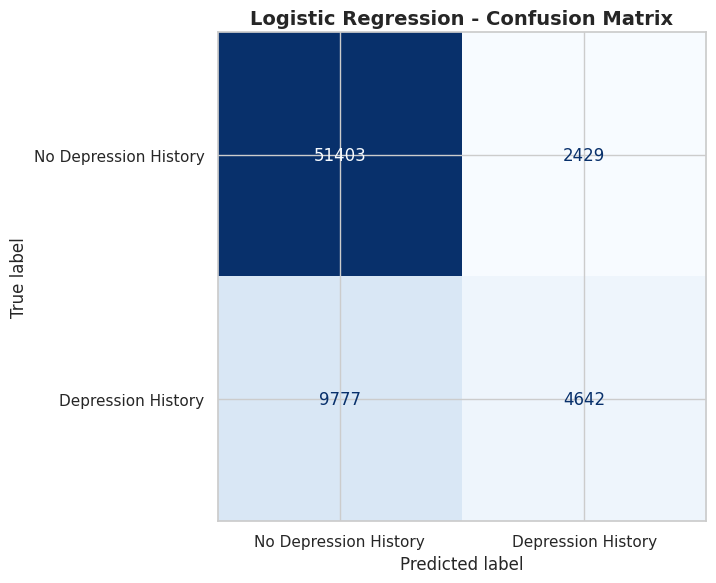

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_lr = confusion_matrix(
    y_val,
    y_val_pred_lr,
    labels=[0, 1]
)

# Display numerical confusion matrix
print("Logistic Regression Confusion Matrix:")
print(cm_lr)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=[
        "No Depression History",
        "Depression History"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title(
    "Logistic Regression - Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Confusion Matrix Interpretation

The baseline Logistic Regression model correctly classified 51,403 respondents without reported depression history and 4,642 respondents with reported depression history.

However, it incorrectly classified 9,777 respondents with depression history as negative, producing a relatively low positive-class recall of 32.19%.

This indicates that the model is biased toward predicting the majority class at the default threshold of 0.5. Further experiments with class weighting and classification thresholds are needed to improve the identification of positive cases.



### **Logistic Regression ROC Curve**

The Receiver Operating Characteristic (ROC) curve illustrates the trade-off between the true positive rate and false positive rate across different classification thresholds.

The Area Under the Curve (AUC) summarizes the model's ability to distinguish between respondents with and without reported depression history.


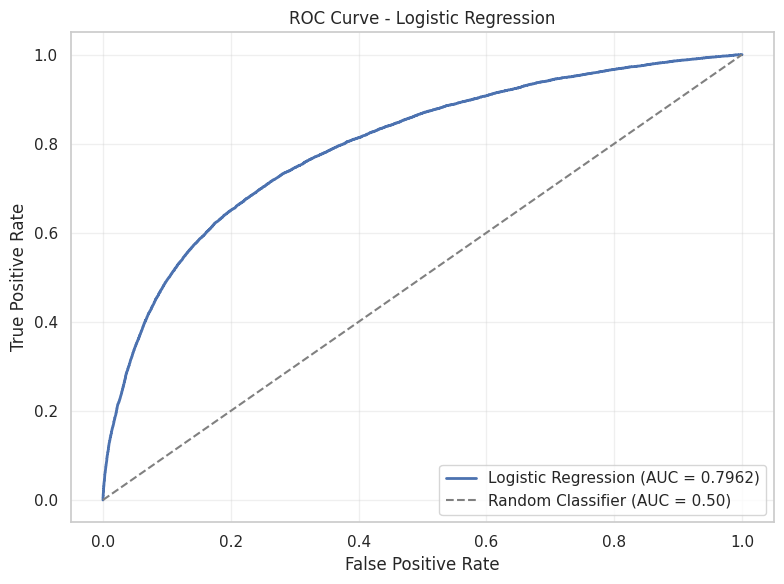

In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_val,
    y_val_prob_lr
)

# Calculate ROC-AUC
auc_lr = roc_auc_score(y_val, y_val_prob_lr)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.4f})",
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### **Logistic Regression Hyperparameter Experiments**

This experiment evaluates the effect of regularization strength and class weighting on Logistic Regression performance.

Six configurations are compared using C values of 0.1, 1.0, and 10.0, with and without balanced class weights.

Models are trained on the training set and evaluated on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC. The test set remains reserved for final evaluation.


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import time

# Hyperparameter configurations
experiments = [
    {"C": 0.1, "class_weight": None},
    {"C": 1.0, "class_weight": None},
    {"C": 10.0, "class_weight": None},
    {"C": 0.1, "class_weight": "balanced"},
    {"C": 1.0, "class_weight": "balanced"},
    {"C": 10.0, "class_weight": "balanced"}
]

experiment_results = []
lr_experiment_models = {}

for config in experiments:

    model = LogisticRegression(
        C=config["C"],
        class_weight=config["class_weight"],
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    )

    start = time.time()

    model.fit(X_train_processed, y_train)

    elapsed = time.time() - start

    predictions = model.predict(X_val_processed)
    probabilities = model.predict_proba(X_val_processed)[:, 1]

    name = (
        f"LR_C{config['C']}_"
        f"{config['class_weight'] or 'none'}"
    )

    lr_experiment_models[name] = model

    experiment_results.append({
        "Experiment": name,
        "C": config["C"],
        "Class Weight": str(config["class_weight"]),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Training Time": elapsed
    })

# Create results table
lr_experiment_df = pd.DataFrame(experiment_results)

display(
    lr_experiment_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)


,Experiment,C,Class Weight,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
3,LR_C0.1_balanced,0.1,balanced,0.7717,0.4708,0.6521,0.5468,0.7984,2.6678
4,LR_C1.0_balanced,1.0,balanced,0.7715,0.4706,0.6520,0.5466,0.7984,2.7967
5,LR_C10.0_balanced,10.0,balanced,0.7715,0.4706,0.6520,0.5466,0.7984,3.5653
1,LR_C1.0_none,1.0,None,0.8212,0.6565,0.3219,0.4320,0.7962,3.3250
2,LR_C10.0_none,10.0,None,0.8212,0.6565,0.3219,0.4320,0.7961,2.8508
0,LR_C0.1_none,0.1,None,0.8210,0.6558,0.3217,0.4316,0.7962,3.2662



### Logistic Regression Optimization Findings

Class weighting had a substantial effect on Logistic Regression performance. The balanced model with C=0.1 achieved the highest validation F1-score of 0.5468, compared with 0.4320 for the baseline.

Recall increased from 32.19% to 65.21%, while precision decreased from 65.65% to 47.08%. This demonstrates a trade-off between identifying more positive cases and producing additional false positives.

Changing regularization strength had relatively little impact within the tested configurations. The balanced C=0.1 model was selected as the best Logistic Regression candidate based on validation F1-score.


Optimized Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.80      0.85     53832
           1       0.47      0.65      0.55     14419

    accuracy                           0.77     68251
   macro avg       0.68      0.73      0.70     68251
weighted avg       0.81      0.77      0.78     68251


Confusion Matrix:
[[43264 10568]
 [ 5016  9403]]


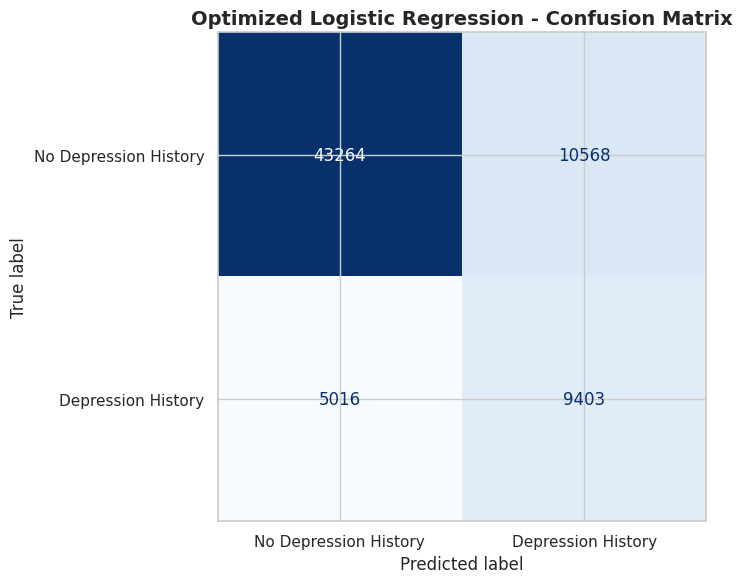

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Retrieve the best Logistic Regression model
best_lr = lr_experiment_models["LR_C0.1_balanced"]

# Generate predictions
y_val_pred_best_lr = best_lr.predict(X_val_processed)

# Display classification report
print("Optimized Logistic Regression Classification Report:")
print(classification_report(y_val, y_val_pred_best_lr))

# Calculate confusion matrix
cm_best_lr = confusion_matrix(
    y_val,
    y_val_pred_best_lr,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm_best_lr)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_lr,
    display_labels=[
        "No Depression History",
        "Depression History"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Optimized Logistic Regression - Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Optimized Logistic Regression Interpretation

The optimized Logistic Regression model reduced false negatives from 9,777 to 5,016, representing a reduction of approximately 48.7%.

True positive predictions increased from 4,642 to 9,403, demonstrating improved identification of respondents with reported depression history.

However, false positives also increased substantially. This highlights the trade-off between improving recall and maintaining precision when applying balanced class weights.



## **Random Forest Classification**

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

This experiment evaluates whether a tree-based model can capture nonlinear relationships between demographic, lifestyle, and health-related predictors more effectively than Logistic Regression.

The initial Random Forest model is evaluated on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC.


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import time

# Initialize Random Forest baseline
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train_processed, y_train)

rf_training_time = time.time() - start_time

# Predict validation labels
y_val_pred_rf = rf_model.predict(X_val_processed)

# Predict probabilities
y_val_prob_rf = rf_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_rf),
    "Training Time (s)": rf_training_time
}

# Display results
print("Random Forest Validation Results")
print("-" * 45)

for metric, value in rf_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))


Random Forest Validation Results
---------------------------------------------
Model: Random Forest
Accuracy: 0.8238
Precision: 0.6791
Recall: 0.3147
F1-score: 0.4300
ROC-AUC: 0.8138
Training Time (s): 43.2891

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.96      0.90     53832
           1       0.68      0.31      0.43     14419

    accuracy                           0.82     68251
   macro avg       0.76      0.64      0.66     68251
weighted avg       0.81      0.82      0.80     68251




### **Random Forest Hyperparameter Experiments**

This experiment investigates the effects of tree depth and class weighting on Random Forest classification performance.

Four configurations are evaluated using different maximum tree depths and class-weighting strategies. Each model is assessed on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC.

The objective is to determine whether model complexity and class balancing improve positive-class identification.


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import time

# Define Random Forest experiments
rf_experiments = [
    {"max_depth": 10, "class_weight": None},
    {"max_depth": 10, "class_weight": "balanced"},
    {"max_depth": 20, "class_weight": None},
    {"max_depth": 20, "class_weight": "balanced"}
]

rf_experiment_results = []
rf_experiment_models = {}

for config in rf_experiments:

    name = (
        f"RF_depth{config['max_depth']}_"
        f"{config['class_weight'] or 'none'}"
    )

    print(f"Training {name}...")

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=config["max_depth"],
        min_samples_leaf=5,
        class_weight=config["class_weight"],
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_train_processed, y_train)
    elapsed = time.time() - start_time

    predictions = model.predict(X_val_processed)
    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    rf_experiment_models[name] = model

    rf_experiment_results.append({
        "Experiment": name,
        "Max Depth": config["max_depth"],
        "Class Weight": str(config["class_weight"]),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Training Time": elapsed
    })

# Create comparison table
rf_experiment_df = pd.DataFrame(rf_experiment_results)

display(
    rf_experiment_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)


Training RF_depth10_none...
Training RF_depth10_balanced...
Training RF_depth20_none...
Training RF_depth20_balanced...


,Experiment,Max Depth,Class Weight,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
3,RF_depth20_balanced,20,balanced,0.7717,0.4725,0.6921,0.5616,0.8135,47.8818
1,RF_depth10_balanced,10,balanced,0.7476,0.4416,0.7353,0.5518,0.8112,32.3543
2,RF_depth20_none,20,None,0.8245,0.6693,0.3346,0.4461,0.8134,49.1209
0,RF_depth10_none,10,None,0.8189,0.7006,0.2493,0.3677,0.8106,33.1731



### Random Forest Optimization Findings

The balanced Random Forest model with a maximum depth of 20 achieved the highest validation F1-score of 0.5616, with recall of 69.21% and ROC-AUC of 0.8135.

Applying balanced class weights substantially improved positive-class recall compared with the unweighted models. However, this improvement came with lower precision and accuracy.

The depth-10 balanced model achieved the highest recall (73.53%), while the depth-20 balanced model provided a better balance between precision and recall.



### **Optimized Random Forest Confusion Matrix**

The best Random Forest configuration is evaluated using a confusion matrix to examine true positives, true negatives, false positives, and false negatives.

The analysis focuses on the model's ability to identify respondents with reported depression history and the trade-off between improved recall and additional false-positive predictions.


Optimized Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.79      0.85     53832
           1       0.47      0.69      0.56     14419

    accuracy                           0.77     68251
   macro avg       0.69      0.74      0.70     68251
weighted avg       0.81      0.77      0.79     68251


Confusion Matrix:
[[42689 11143]
 [ 4439  9980]]


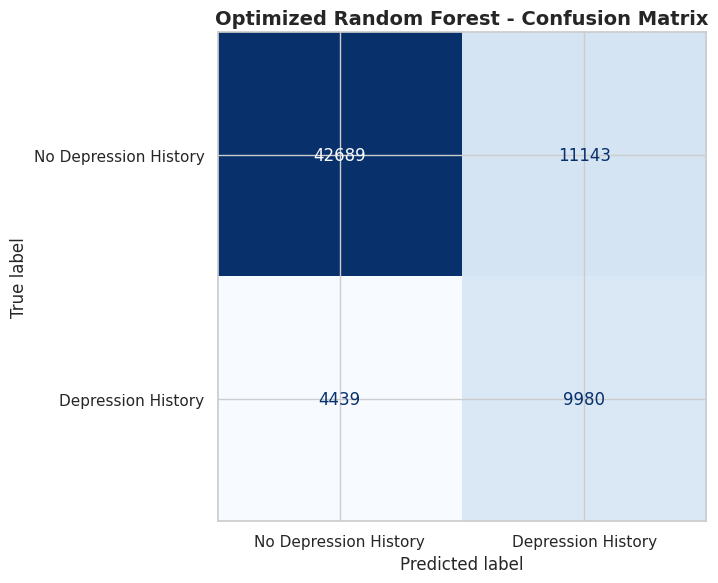

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Retrieve the best Random Forest model
best_rf = rf_experiment_models["RF_depth20_balanced"]

# Generate validation predictions
y_val_pred_best_rf = best_rf.predict(X_val_processed)

# Classification report
print("Optimized Random Forest Classification Report:")
print(classification_report(y_val, y_val_pred_best_rf))

# Calculate confusion matrix
cm_best_rf = confusion_matrix(
    y_val,
    y_val_pred_best_rf,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm_best_rf)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_rf,
    display_labels=[
        "No Depression History",
        "Depression History"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Optimized Random Forest - Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Optimized Random Forest Interpretation

The optimized Random Forest model correctly identified 9,980 respondents with reported depression history while missing 4,439 positive cases.

Compared with optimized Logistic Regression, Random Forest reduced false negatives by 577 but increased false positives by 575.

The model achieved a positive-class recall of 69.21% and an F1-score of 0.5616, making it the strongest model tested so far based on validation F1-score.



##  **Gradient Boosting Classification**

Histogram-Based Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially to improve predictive performance.

This experiment evaluates whether gradient boosting can outperform Logistic Regression and Random Forest in predicting self-reported depression history.

The model is evaluated using accuracy, precision, recall, F1-score, and ROC-AUC on the validation dataset.


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import time

# Initialize Gradient Boosting model
gb_model = HistGradientBoostingClassifier(
    max_iter=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42
)

# Train the model
start_time = time.time()

gb_model.fit(X_train_processed, y_train)

gb_training_time = time.time() - start_time

# Predict validation labels
y_val_pred_gb = gb_model.predict(X_val_processed)

# Predict probabilities
y_val_prob_gb = gb_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_val, y_val_pred_gb),
    "Precision": precision_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_gb, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_gb),
    "Training Time (s)": gb_training_time
}

# Display results
print("Gradient Boosting Validation Results")
print("-" * 45)

for metric, value in gb_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_gb))


Gradient Boosting Validation Results
---------------------------------------------
Model: Gradient Boosting
Accuracy: 0.8257
Precision: 0.6500
Recall: 0.3796
F1-score: 0.4793
ROC-AUC: 0.8168
Training Time (s): 17.1020

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     53832
           1       0.65      0.38      0.48     14419

    accuracy                           0.83     68251
   macro avg       0.75      0.66      0.69     68251
weighted avg       0.81      0.83      0.81     68251




### **Gradient Boosting Hyperparameter Experiment**s

This experiment evaluates the effects of learning rate and class weighting on Histogram-Based Gradient Boosting performance.

Four configurations are compared using learning rates of 0.05 and 0.1, with and without balanced class weights.

Performance is evaluated on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC.


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import time

# Define hyperparameter experiments
gb_experiments = [
    {"learning_rate": 0.05, "class_weight": None},
    {"learning_rate": 0.1, "class_weight": None},
    {"learning_rate": 0.05, "class_weight": "balanced"},
    {"learning_rate": 0.1, "class_weight": "balanced"}
]

gb_experiment_results = []
gb_experiment_models = {}

for config in gb_experiments:

    name = (
        f"GB_lr{config['learning_rate']}_"
        f"{config['class_weight'] or 'none'}"
    )

    print(f"Training {name}...")

    model = HistGradientBoostingClassifier(
        max_iter=100,
        max_depth=6,
        learning_rate=config["learning_rate"],
        class_weight=config["class_weight"],
        random_state=42
    )

    start = time.time()

    model.fit(X_train_processed, y_train)

    elapsed = time.time() - start

    predictions = model.predict(X_val_processed)
    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    gb_experiment_models[name] = model

    gb_experiment_results.append({
        "Experiment": name,
        "Learning Rate": config["learning_rate"],
        "Class Weight": str(config["class_weight"]),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Training Time": elapsed
    })

# Create results table
gb_experiment_df = pd.DataFrame(gb_experiment_results)

display(
    gb_experiment_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)


Training GB_lr0.05_none...
Training GB_lr0.1_none...
Training GB_lr0.05_balanced...
Training GB_lr0.1_balanced...


,Experiment,Learning Rate,Class Weight,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
3,GB_lr0.1_balanced,0.10,balanced,0.7573,0.4537,0.7279,0.5589,0.8168,17.8623
2,GB_lr0.05_balanced,0.05,balanced,0.7581,0.4545,0.7249,0.5587,0.8154,18.5164
1,GB_lr0.1_none,0.10,None,0.8257,0.6500,0.3796,0.4793,0.8168,17.3137
0,GB_lr0.05_none,0.05,None,0.8250,0.6504,0.3708,0.4723,0.8154,19.5314



### Gradient Boosting Optimization Findings

Applying balanced class weights substantially improved positive-class recall in Gradient Boosting, increasing it from 37.96% to 72.79% at a learning rate of 0.1.

The balanced model achieved an F1-score of 0.5589 and ROC-AUC of 0.8168. However, precision decreased to 45.37%, demonstrating a trade-off between detecting positive cases and increasing false-positive predictions.

The learning rate had a relatively small effect compared with class weighting. Random Forest retained the highest validation F1-score, while Gradient Boosting achieved the highest recall and ROC-AUC among the selected models.



### **Classification Threshold Optimization**

The classification threshold determines the probability at which a respondent is assigned to the positive class.

This experiment evaluates multiple probability thresholds for the best Gradient Boosting model to investigate whether positive-class F1-score can be improved without retraining.

Threshold selection is performed exclusively on validation data, preserving the test set for final evaluation.


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Retrieve optimized Gradient Boosting model
best_gb = gb_experiment_models["GB_lr0.1_balanced"]

# Predict probabilities on validation data
gb_probabilities = best_gb.predict_proba(
    X_val_processed
)[:, 1]

# Test different thresholds
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        gb_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)

# Identify best threshold
best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(), "Threshold"
]

print("Best validation F1 threshold:", best_threshold)


,Threshold,Accuracy,Precision,Recall,F1
8,0.60,0.7934,0.5087,0.6421,0.5677
7,0.55,0.7770,0.4806,0.6870,0.5656
9,0.65,0.8063,0.5381,0.5879,0.5619
6,0.50,0.7573,0.4537,0.7279,0.5589
5,0.45,0.7320,0.4256,0.7683,0.5478
10,0.70,0.8171,0.5740,0.5203,0.5458
4,0.40,0.7022,0.3986,0.8045,0.5331
3,0.35,0.6633,0.3693,0.8390,0.5129
11,0.75,0.8229,0.6123,0.4412,0.5128
2,0.30,0.6132,0.3390,0.8748,0.4887


Best validation F1 threshold: 0.6



### Threshold Optimization Findings

The Gradient Boosting model achieved its highest validation F1-score of 0.5677 at a classification threshold of 0.60.

Increasing the threshold from 0.50 to 0.60 improved precision from 45.37% to 50.87%, while recall decreased from 72.79% to 64.21%.

This demonstrates that adjusting the decision threshold can improve the balance between precision and recall without retraining the model.



## 2. Deep Learning Classification

### TensorFlow Data Preparation

A deep learning approach is implemented using TensorFlow and Keras to classify self-reported depression history.

The preprocessed features are converted to float32 and organized into efficient input pipelines using the tf.data API.

The training, validation, and testing subsets remain consistent with those used in traditional machine learning to support meaningful model comparisons.


In [ ]:

import tensorflow as tf
import numpy as np

print("TensorFlow version:", tf.__version__)

# Convert preprocessed features to float32
X_train_dl = X_train_processed.astype(np.float32)
X_val_dl = X_val_processed.astype(np.float32)
X_test_dl = X_test_processed.astype(np.float32)

# Convert labels to float32
y_train_dl = y_train.to_numpy().astype(np.float32)
y_val_dl = y_val.to_numpy().astype(np.float32)
y_test_dl = y_test.to_numpy().astype(np.float32)

print("\nTraining features:", X_train_dl.shape)
print("Validation features:", X_val_dl.shape)
print("Testing features:", X_test_dl.shape)

print("\nTraining labels:", y_train_dl.shape)

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Create tf.data datasets
batch_size = 256

train_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_train_dl, y_train_dl)
    )
    .shuffle(10000, seed=42)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_val_dl, y_val_dl)
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_test_dl, y_test_dl)
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

print("\ntf.data pipelines created successfully!")

print("Number of input features:", X_train_dl.shape[1])


TensorFlow version: 2.21.0

Training features: (318504, 58)
Validation features: (68251, 58)
Testing features: (68251, 58)

Training labels: (318504,)

tf.data pipelines created successfully!
Number of input features: 58



### **Baseline Neural Network Architecture**

A feedforward neural network is constructed using the Keras Sequential API.

The architecture contains two hidden Dense layers with 64 and 32 neurons, both using ReLU activation. A single sigmoid output neuron produces probabilities for the binary classification task.

The model is trained using the Adam optimizer and binary cross-entropy loss. Early stopping monitors validation loss to reduce overfitting.


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed
tf.keras.utils.set_random_seed(42)

# Build baseline neural network
ann_baseline = keras.Sequential([
    keras.Input(shape=(X_train_dl.shape[1],)),

    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")
], name="ANN_Baseline")

# Compile model
ann_baseline.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

# Display architecture
ann_baseline.summary()


Model: "ANN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 0 (0.00 B)


### E**xperiment 1; Baseline Neural Network Training**
The baseline neural network is trained using the training tf.data pipeline and evaluated during training on the validation pipeline.

Early stopping monitors validation loss, with the best-performing weights restored when training stops. Training and validation histories are retained for learning curve analysis.


In [ ]:

import time

# Configure early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the model
start_time = time.time()

history_baseline = ann_baseline.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=40,
    callbacks=[early_stopping],
    verbose=1
)

ann_training_time = time.time() - start_time

print(
    "\nTraining completed in",
    round(ann_training_time, 2),
    "seconds"
)

print(
    "Epochs completed:",
    len(history_baseline.history["loss"])
)


Epoch 1/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8229 - auc: 0.8061 - loss: 0.4055 - val_accuracy: 0.8249 - val_auc: 0.8127 - val_loss: 0.4011
Epoch 2/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8261 - auc: 0.8151 - loss: 0.3980 - val_accuracy: 0.8256 - val_auc: 0.8140 - val_loss: 0.3998
Epoch 3/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8265 - auc: 0.8168 - loss: 0.3967 - val_accuracy: 0.8262 - val_auc: 0.8144 - val_loss: 0.3988
Epoch 4/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8268 - auc: 0.8178 - loss: 0.3959 - val_accuracy: 0.8251 - val_auc: 0.8142 - val_loss: 0.3992
Epoch 5/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8278 - auc: 0.8186 - loss: 0.3952 - val_accuracy: 0.8254 - val_auc: 0.8146 - val_loss: 0.3997
Epoch 6/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8280 - auc: 0.8192 - loss: 0.3947 - val_accuracy: 0.8255 - val_auc: 0.8151 - val_loss: 0.3985
Epoch 7/40
1245/1245 ━━━━━━━


### Neural Network Learning Curves

Training and validation learning curves are plotted to examine model convergence and generalization.

Binary cross-entropy loss and accuracy are compared across epochs to identify possible overfitting or underfitting.


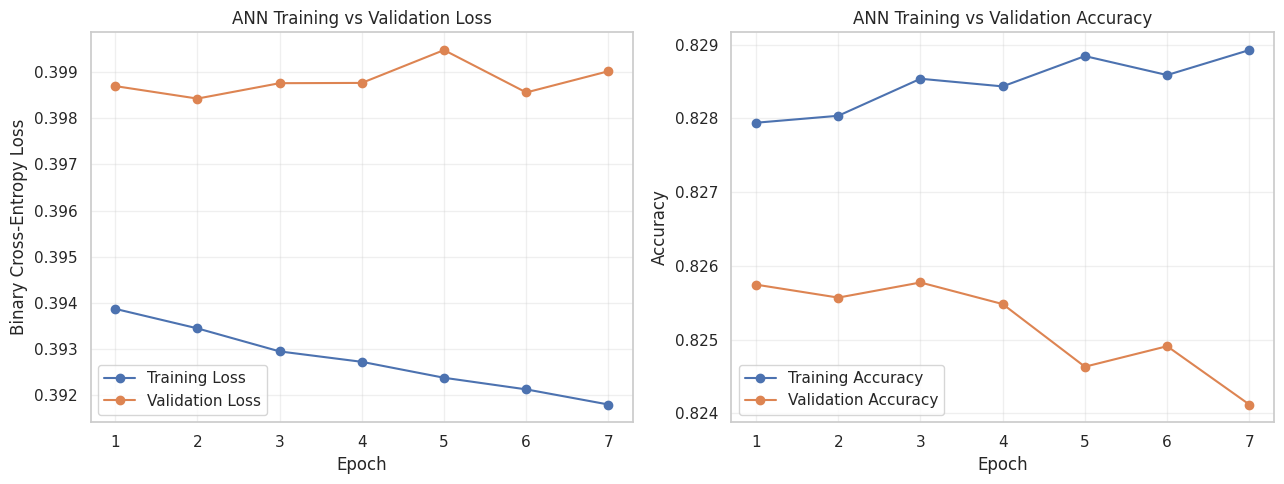

Epochs completed: 7
Best epoch by validation loss: 2
Lowest validation loss: 0.3984


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

history = history_baseline.history
epochs = np.arange(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot loss
axes[0].plot(
    epochs, history["loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[0].set_title("ANN Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot accuracy
axes[1].plot(
    epochs, history["accuracy"],
    marker="o", label="Training Accuracy"
)
axes[1].plot(
    epochs, history["val_accuracy"],
    marker="o", label="Validation Accuracy"
)
axes[1].set_title("ANN Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display best epoch
best_epoch = np.argmin(history["val_loss"]) + 1

print("Epochs completed:", len(epochs))
print("Best epoch by validation loss:", best_epoch)
print("Lowest validation loss:",
      round(min(history["val_loss"]), 4))



### Baseline ANN Learning Curve Analysis

The baseline neural network trained for seven epochs before early stopping was triggered. The lowest validation loss of 0.3984 occurred at epoch 2.

Although training loss continued decreasing, validation loss fluctuated without sustained improvement. Training accuracy increased slightly while validation accuracy declined, suggesting mild overfitting.

Early stopping prevented unnecessary additional training and restored the weights associated with the lowest validation loss.



### **Baseline Neural Network Validation Evaluation**
The baseline neural network is evaluated on the validation dataset using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

These metrics support comparison with traditional machine learning models and provide insight into performance on the minority positive class.


Baseline ANN Validation Results
----------------------------------------
Accuracy: 0.8256
Precision: 0.6580
Recall: 0.3630
F1-score: 0.4679
ROC-AUC: 0.8149

Classification Report:
              precision    recall  f1-score   support

         0.0       0.85      0.95      0.90     53832
         1.0       0.66      0.36      0.47     14419

    accuracy                           0.83     68251
   macro avg       0.75      0.66      0.68     68251
weighted avg       0.81      0.83      0.81     68251



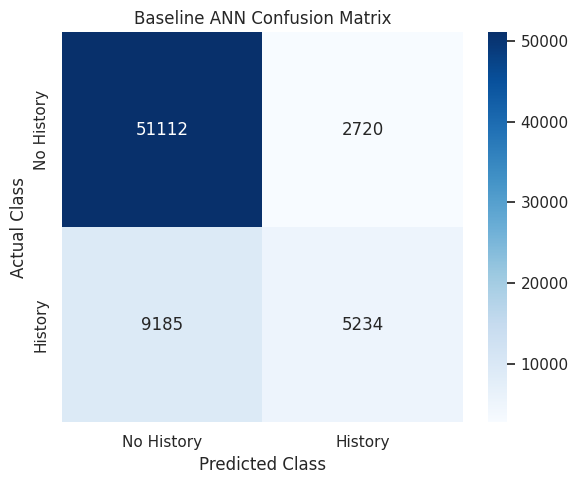

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict validation probabilities
ann_val_prob = ann_baseline.predict(
    val_dataset,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
ann_val_pred = (ann_val_prob >= 0.5).astype(int)

# Calculate metrics
ann_baseline_results = {
    "Accuracy": accuracy_score(y_val_dl, ann_val_pred),
    "Precision": precision_score(
        y_val_dl, ann_val_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val_dl, ann_val_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_dl, ann_val_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_dl, ann_val_prob
    )
}

print("Baseline ANN Validation Results")
print("-" * 40)

for metric, value in ann_baseline_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_dl, ann_val_pred,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_val_dl, ann_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No History", "History"],
    yticklabels=["No History", "History"]
)

plt.title("Baseline ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()



##**Experiment 2; Class-Weighted Neural Network Experiment**

The baseline ANN showed relatively low recall for respondents reporting depression history.

To address class imbalance, a second neural network is trained using class weights calculated from the training labels.

The architecture, optimizer, and learning rate are kept consistent with the baseline to isolate the effect of class weighting

In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
import time

# Calculate class weights from training labels only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_dl.astype(int)
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:", class_weights)

# Rebuild same architecture
tf.keras.utils.set_random_seed(42)

ann_weighted = keras.Sequential([
    keras.Input(shape=(X_train_dl.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="ANN_ClassWeighted")

ann_weighted.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

# Early stopping
early_stopping_weighted = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train weighted ANN
start_time = time.time()

history_weighted = ann_weighted.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=40,
    class_weight=class_weights,
    callbacks=[early_stopping_weighted],
    verbose=1
)

weighted_training_time = time.time() - start_time

print("\nTraining time:",
      round(weighted_training_time, 2), "seconds")

print("Epochs completed:",
      len(history_weighted.history["loss"]))


Class weights: {0: 0.6339220673760135, 1: 2.3667573231084758}
Epoch 1/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7589 - auc: 0.8073 - loss: 0.5355 - val_accuracy: 0.7444 - val_auc: 0.8124 - val_loss: 0.5501
Epoch 2/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7562 - auc: 0.8153 - loss: 0.5262 - val_accuracy: 0.7420 - val_auc: 0.8138 - val_loss: 0.5464
Epoch 3/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7552 - auc: 0.8170 - loss: 0.5242 - val_accuracy: 0.7547 - val_auc: 0.8147 - val_loss: 0.5207
Epoch 4/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7548 - auc: 0.8183 - loss: 0.5227 - val_accuracy: 0.7424 - val_auc: 0.8147 - val_loss: 0.5386
Epoch 5/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7546 - auc: 0.8190 - loss: 0.5218 - val_accuracy: 0.7401 - val_auc: 0.8149 - val_loss: 0.5412
Epoch 6/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7546 - auc: 0.8197 - loss: 0.5210 - val_accuracy: 0.7543 - v

In [12]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict validation probabilities
ann_weighted_prob = ann_weighted.predict(
    val_dataset,
    verbose=0
).ravel()

# Apply default classification threshold
ann_weighted_pred = (
    ann_weighted_prob >= 0.5
).astype(int)

# Calculate evaluation metrics
ann_weighted_results = {
    "Accuracy": accuracy_score(y_val_dl, ann_weighted_pred),
    "Precision": precision_score(
        y_val_dl, ann_weighted_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val_dl, ann_weighted_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_dl, ann_weighted_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_dl, ann_weighted_prob
    )
}

print("Class-Weighted ANN Validation Results")
print("-" * 45)

for metric, value in ann_weighted_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_dl,
    ann_weighted_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_dl,
    ann_weighted_pred
))


Class-Weighted ANN Validation Results
---------------------------------------------
Accuracy: 0.7623
Precision: 0.4597
Recall: 0.7149
F1-score: 0.5596
ROC-AUC: 0.8145

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      0.77      0.84     53832
         1.0       0.46      0.71      0.56     14419

    accuracy                           0.76     68251
   macro avg       0.69      0.74      0.70     68251
weighted avg       0.82      0.76      0.78     68251


Confusion Matrix:
[[41718 12114]
 [ 4111 10308]]


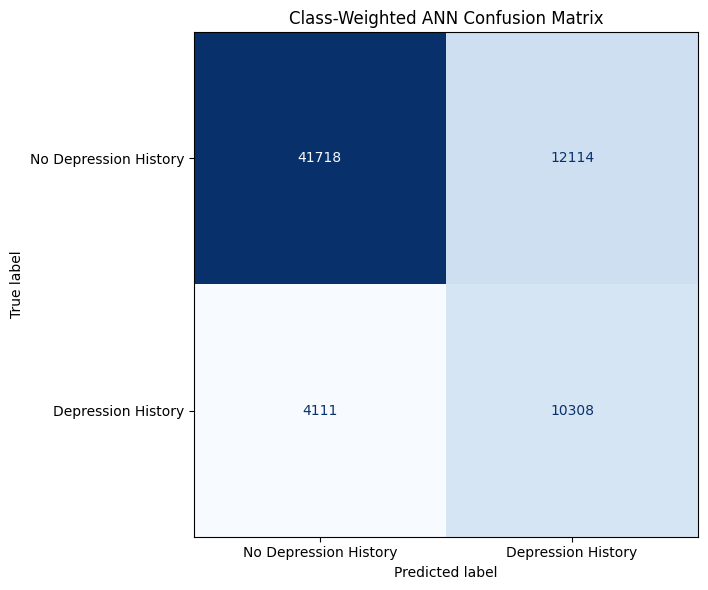

In [14]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm_weighted = confusion_matrix(
    y_val_dl,
    ann_weighted_pred
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted,
    display_labels=["No Depression History", "Depression History"]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Class-Weighted ANN Confusion Matrix")
plt.tight_layout()
plt.show()



### Class-Weighted ANN Training and Validation Curves

The following plots show the training and validation loss and accuracy across epochs to assess convergence and potential overfitting.


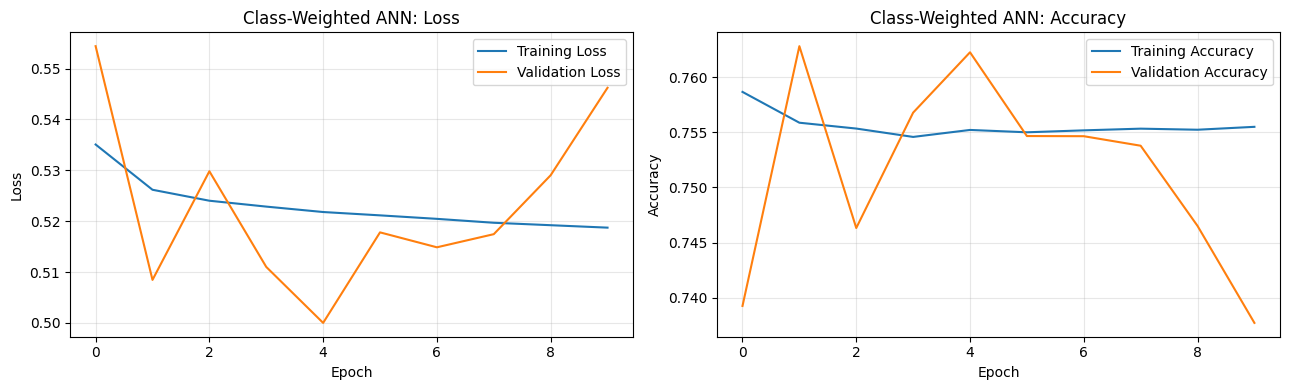

In [13]:

import matplotlib.pyplot as plt

history = history_weighted.history

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss curves
axes[0].plot(history["loss"], label="Training Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Class-Weighted ANN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curves
axes[1].plot(history["accuracy"], label="Training Accuracy")
axes[1].plot(history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Class-Weighted ANN: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation of Class-Weighted ANN Learning Curves**

The class-weighted ANN demonstrated a gradual reduction in training loss across epochs, indicating continued learning. However, validation loss fluctuated and reached its minimum at epoch 5 before increasing, suggesting the onset of overfitting. Training accuracy remained relatively stable, while validation accuracy showed noticeable fluctuations. Early stopping helped prevent unnecessary training and restored the model weights from the epoch with the lowest validation loss. Overall, the model achieved a validation F1-score of 0.5596 and recall of 0.7149, indicating improved identification of respondents reporting depression history compared with the baseline ANN, at the expense of precision.


###Class-Weighted ANN Threshold Optimization

Different classification thresholds were evaluated on the validation dataset to investigate the precision-recall trade-off.

The threshold that maximizes the F1-score was selected for comparison with the traditional machine learning models.

The test dataset remains untouched during threshold optimization.


In [15]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Test thresholds between 0.20 and 0.80
thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)

results = []

for threshold in thresholds:
    predictions = (ann_weighted_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_dl, predictions),
        "Precision": precision_score(
            y_val_dl, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_dl, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_dl, predictions, zero_division=0
        )
    })

ann_threshold_df = pd.DataFrame(results)

display(ann_threshold_df.round(4))

# Identify best threshold
best_row = ann_threshold_df.loc[
    ann_threshold_df["F1-score"].idxmax()
]

best_ann_threshold = float(best_row["Threshold"])

print("\nBest ANN threshold:", best_ann_threshold)
print("Best validation F1-score:",
      round(best_row["F1-score"], 4))


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.20,0.5069,0.2907,0.9260,0.4424
1,0.25,0.5825,0.3226,0.8876,0.4732
2,0.30,0.6410,0.3546,0.8525,0.5008
3,0.35,0.6841,0.3837,0.8173,0.5222
4,0.40,0.7155,0.4095,0.7842,0.5380
5,0.45,0.7403,0.4336,0.7490,0.5493
6,0.50,0.7623,0.4597,0.7149,0.5596
7,0.55,0.7810,0.4869,0.6764,0.5662
8,0.60,0.7968,0.5156,0.6296,0.5669
9,0.65,0.8092,0.5464,0.5699,0.5579



Best ANN threshold: 0.6
Best validation F1-score: 0.5669


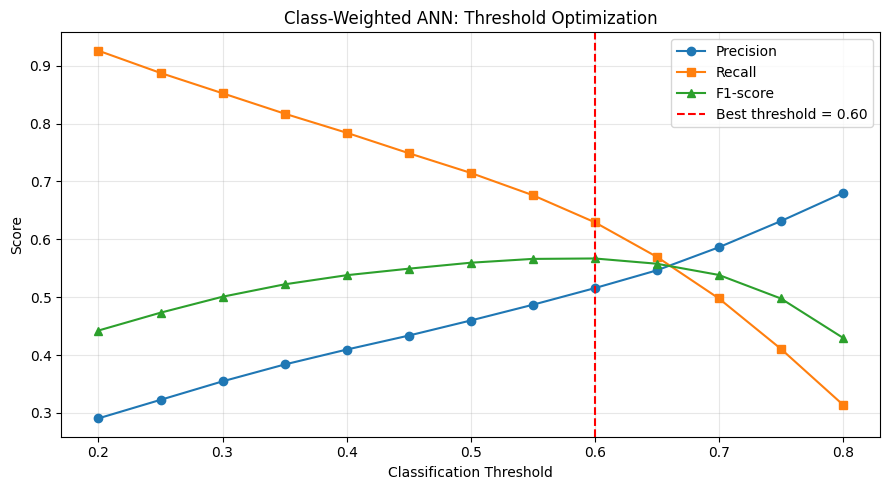

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    ann_threshold_df["Threshold"],
    ann_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    ann_threshold_df["Threshold"],
    ann_threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    ann_threshold_df["Threshold"],
    ann_threshold_df["F1-score"],
    marker="^",
    label="F1-score"
)

plt.axvline(
    x=best_ann_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_ann_threshold:.2f}"
)

plt.title("Class-Weighted ANN: Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## **Experiment 3: Class-Weighted ANN with Dropout**

This experiment investigates whether dropout regularization improves the generalization performance of the class-weighted neural network.

The architecture retains two hidden layers with 64 and 32 neurons, while introducing dropout after each hidden layer to reduce overfitting.

The model uses the same preprocessed training and validation datasets and balanced class weights as the previous experiment.


In [17]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

# Experiment 3: Weighted ANN with dropout
ann_dropout = keras.Sequential([
    keras.Input(shape=(X_train_dl.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
], name="ANN_ClassWeighted_Dropout")

ann_dropout.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

ann_dropout.summary()


Model: "ANN_ClassWeighted_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:

import time
import numpy as np
from tensorflow import keras

# Early stopping for dropout experiment
early_stopping_dropout = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train Experiment 3
start_time = time.time()

history_dropout = ann_dropout.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=40,
    class_weight=class_weights,
    callbacks=[early_stopping_dropout],
    verbose=1
)

dropout_training_time = time.time() - start_time

print("\nExperiment 3 Training Completed!")
print("Training time:",
      round(dropout_training_time, 2), "seconds")

print("Epochs completed:",
      len(history_dropout.history["loss"]))

print("Best epoch:",
      np.argmin(history_dropout.history["val_loss"]) + 1)


Epoch 1/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7472 - auc: 0.7936 - loss: 0.5521 - val_accuracy: 0.7565 - val_auc: 0.8110 - val_loss: 0.5249
Epoch 2/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7522 - auc: 0.8076 - loss: 0.5360 - val_accuracy: 0.7536 - val_auc: 0.8130 - val_loss: 0.5258
Epoch 3/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7532 - auc: 0.8108 - loss: 0.5322 - val_accuracy: 0.7456 - val_auc: 0.8140 - val_loss: 0.5459
Epoch 4/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7542 - auc: 0.8123 - loss: 0.5304 - val_accuracy: 0.7541 - val_auc: 0.8147 - val_loss: 0.5251
Epoch 5/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7551 - auc: 0.8130 - loss: 0.5295 - val_accuracy: 0.7499 - val_auc: 0.8151 - val_loss: 0.5393
Epoch 6/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7553 - auc: 0.8137 - loss: 0.5287 - val_accuracy: 0.7579 - val_auc: 0.8149 - val_loss: 0.5194
Epoch 7/40
1245/1245 ━━━━━━━

In [19]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities on validation data
ann_dropout_prob = ann_dropout.predict(
    val_dataset,
    verbose=0
).ravel()

# Convert probabilities to class predictions
ann_dropout_pred = (
    ann_dropout_prob >= 0.50
).astype(int)

# Calculate evaluation metrics
dropout_results = {
    "Accuracy": accuracy_score(y_val_dl, ann_dropout_pred),
    "Precision": precision_score(
        y_val_dl, ann_dropout_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val_dl, ann_dropout_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_dl, ann_dropout_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_dl, ann_dropout_prob
    )
}

print("Experiment 3: Dropout ANN Validation Results")
print("-" * 45)

for metric, value in dropout_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_dl,
    ann_dropout_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_dl,
    ann_dropout_pred
))


Experiment 3: Dropout ANN Validation Results
---------------------------------------------
Accuracy: 0.7544
Precision: 0.4502
Recall: 0.7348
F1-score: 0.5583
ROC-AUC: 0.8156

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      0.76      0.83     53832
         1.0       0.45      0.73      0.56     14419

    accuracy                           0.75     68251
   macro avg       0.68      0.75      0.69     68251
weighted avg       0.82      0.75      0.77     68251


Confusion Matrix:
[[40893 12939]
 [ 3824 10595]]


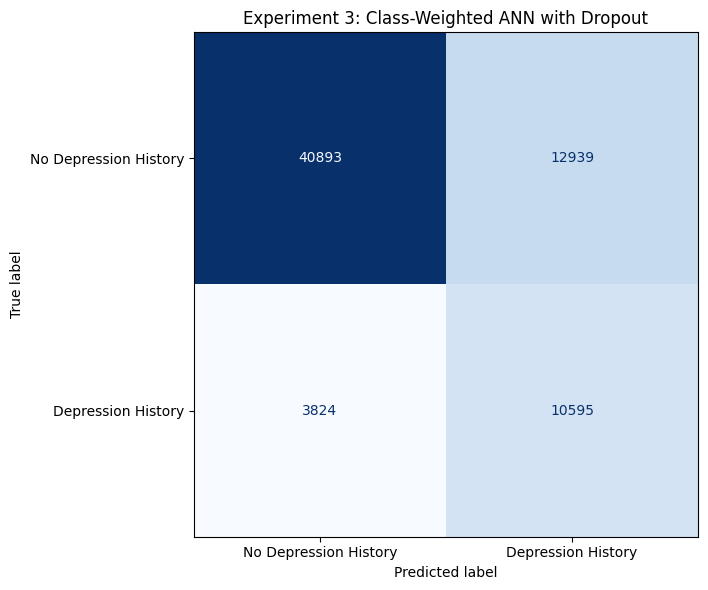

In [20]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Generate dropout ANN confusion matrix
cm_dropout = confusion_matrix(
    y_val_dl,
    ann_dropout_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dropout,
    display_labels=[
        "No Depression History",
        "Depression History"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Experiment 3: Class-Weighted ANN with Dropout")
plt.tight_layout()
plt.show()


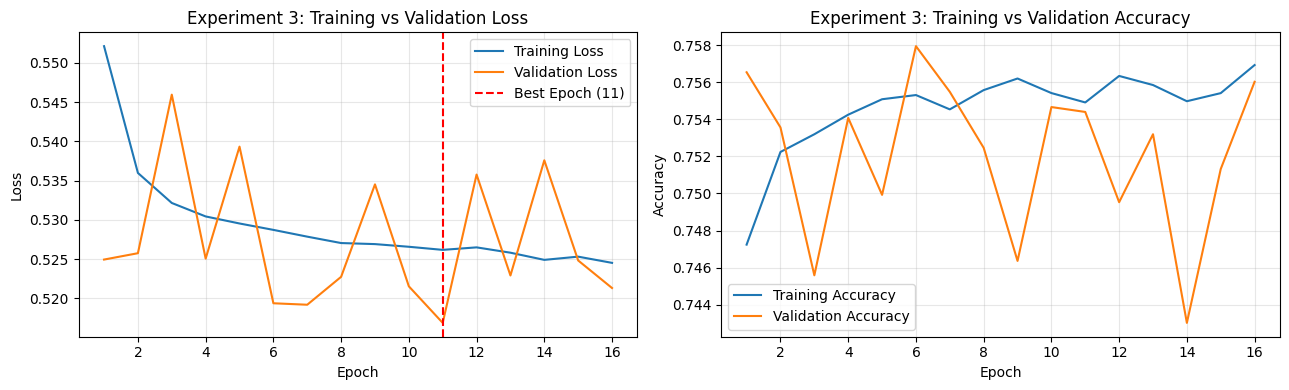

In [21]:

import matplotlib.pyplot as plt

# Retrieve Experiment 3 training history
dropout_history = history_dropout.history

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

epochs = range(1, len(dropout_history["loss"]) + 1)

# Plot training and validation loss
axes[0].plot(
    epochs,
    dropout_history["loss"],
    label="Training Loss"
)

axes[0].plot(
    epochs,
    dropout_history["val_loss"],
    label="Validation Loss"
)

axes[0].axvline(
    x=11,
    color="red",
    linestyle="--",
    label="Best Epoch (11)"
)

axes[0].set_title("Experiment 3: Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot training and validation accuracy
axes[1].plot(
    epochs,
    dropout_history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    dropout_history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Experiment 3: Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Dropout ANN Threshold Optimization

Classification thresholds between 0.20 and 0.80 are evaluated using the validation dataset. The threshold with the highest F1-score is selected for comparison with the previous ANN experiments.


In [22]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

dropout_threshold_results = []

for threshold in np.round(np.arange(0.20, 0.81, 0.05), 2):

    predictions = (
        ann_dropout_prob >= threshold
    ).astype(int)

    dropout_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_dl, predictions),
        "Precision": precision_score(
            y_val_dl, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_dl, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_dl, predictions, zero_division=0
        )
    })

dropout_threshold_df = pd.DataFrame(
    dropout_threshold_results
)

display(dropout_threshold_df.round(4))

best_dropout_row = dropout_threshold_df.loc[
    dropout_threshold_df["F1-score"].idxmax()
]

best_dropout_threshold = float(
    best_dropout_row["Threshold"]
)

print("\nBest Dropout ANN Threshold:",
      best_dropout_threshold)

print("Best Validation F1-score:",
      round(best_dropout_row["F1-score"], 4))


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.20,0.4875,0.2836,0.9343,0.4351
1,0.25,0.5654,0.3150,0.8996,0.4666
2,0.30,0.6233,0.3443,0.8659,0.4927
3,0.35,0.6673,0.3717,0.8331,0.5141
4,0.40,0.7008,0.3968,0.8005,0.5306
5,0.45,0.7301,0.4234,0.7668,0.5455
6,0.50,0.7544,0.4502,0.7348,0.5583
7,0.55,0.7722,0.4735,0.6989,0.5645
8,0.60,0.7873,0.4975,0.6623,0.5682
9,0.65,0.8003,0.5233,0.6130,0.5646



Best Dropout ANN Threshold: 0.6
Best Validation F1-score: 0.5682


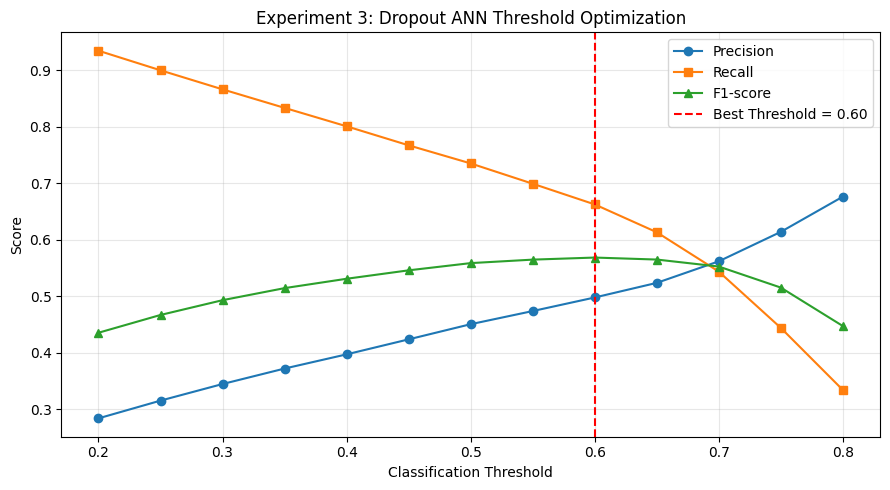

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    dropout_threshold_df["Threshold"],
    dropout_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    dropout_threshold_df["Threshold"],
    dropout_threshold_df["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    dropout_threshold_df["Threshold"],
    dropout_threshold_df["F1-score"],
    marker="^",
    label="F1-score"
)

plt.axvline(
    x=best_dropout_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold = {best_dropout_threshold:.2f}"
)

plt.title("Experiment 3: Dropout ANN Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

import os
import json

# Use the same Google Drive project folder
save_dir = "/content/drive/MyDrive/BRFSS_Depression_Project"
os.makedirs(save_dir, exist_ok=True)

# Save Experiment 3 model
ann_dropout.save(
    os.path.join(save_dir, "ann_dropout.keras")
)

# Save the selected threshold and validation metrics
dropout_metadata = {
    "model": "Class-Weighted ANN with Dropout",
    "selected_threshold": float(best_dropout_threshold),
    "validation_f1": float(best_dropout_row["F1-score"]),
    "validation_accuracy": float(best_dropout_row["Accuracy"]),
    "validation_precision": float(best_dropout_row["Precision"]),
    "validation_recall": float(best_dropout_row["Recall"]),
    "validation_roc_auc": float(dropout_results["ROC-AUC"])
}

with open(
    os.path.join(save_dir, "ann_dropout_metadata.json"),
    "w"
) as file:
    json.dump(dropout_metadata, file, indent=4)

print("Experiment 3 saved successfully!")
print("Model: ann_dropout.keras")
print("Metadata: ann_dropout_metadata.json")
print("Location:", save_dir)


Experiment 3 saved successfully!
Model: ann_dropout.keras
Metadata: ann_dropout_metadata.json
Location: /content/drive/MyDrive/BRFSS_Depression_Project



##  Comparative Analysis of Traditional Machine Learning and Deep Learning

This section compares the validation performance of traditional machine learning algorithms and artificial neural networks.

The comparison focuses on accuracy, precision, recall, F1-score, and ROC-AUC. For models where classification thresholds were optimized, the best tested validation threshold is used.

The test dataset remains reserved for final evaluation.


In [25]:

import pandas as pd

# Consolidated validation results from completed experiments
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (Balanced)",
        "Type": "Traditional ML",
        "Threshold": 0.50,
        "Accuracy": 0.7717,
        "Precision": 0.4708,
        "Recall": 0.6521,
        "F1-score": 0.5468,
        "ROC-AUC": 0.7984
    },
    {
        "Model": "Random Forest (Balanced)",
        "Type": "Traditional ML",
        "Threshold": 0.50,
        "Accuracy": 0.7717,
        "Precision": 0.4725,
        "Recall": 0.6921,
        "F1-score": 0.5616,
        "ROC-AUC": 0.8135
    },
    {
        "Model": "Gradient Boosting (Optimized)",
        "Type": "Traditional ML",
        "Threshold": 0.60,
        "Accuracy": 0.7934,
        "Precision": 0.5087,
        "Recall": 0.6421,
        "F1-score": 0.5677,
        "ROC-AUC": 0.8168
    },
    {
        "Model": "Baseline ANN",
        "Type": "Deep Learning",
        "Threshold": 0.50,
        "Accuracy": 0.8256,
        "Precision": 0.6588,
        "Recall": 0.3630,
        "F1-score": 0.4679,
        "ROC-AUC": 0.8149
    },
    {
        "Model": "Class-Weighted ANN (Optimized)",
        "Type": "Deep Learning",
        "Threshold": 0.60,
        "Accuracy": 0.7968,
        "Precision": 0.5156,
        "Recall": 0.6296,
        "F1-score": 0.5669,
        "ROC-AUC": 0.8145
    },
    {
        "Model": "Dropout ANN (Optimized)",
        "Type": "Deep Learning",
        "Threshold": best_dropout_threshold,
        "Accuracy": float(best_dropout_row["Accuracy"]),
        "Precision": float(best_dropout_row["Precision"]),
        "Recall": float(best_dropout_row["Recall"]),
        "F1-score": float(best_dropout_row["F1-score"]),
        "ROC-AUC": float(dropout_results["ROC-AUC"])
    }
])

# Rank models by validation F1-score
model_comparison = model_comparison.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("Traditional ML vs Deep Learning — Validation Comparison")
display(model_comparison.round(4))


Traditional ML vs Deep Learning — Validation Comparison


,Model,Type,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Dropout ANN (Optimized),Deep Learning,0.6,0.7873,0.4975,0.6623,0.5682,0.8156
1,Gradient Boosting (Optimized),Traditional ML,0.6,0.7934,0.5087,0.6421,0.5677,0.8168
2,Class-Weighted ANN (Optimized),Deep Learning,0.6,0.7968,0.5156,0.6296,0.5669,0.8145
3,Random Forest (Balanced),Traditional ML,0.5,0.7717,0.4725,0.6921,0.5616,0.8135
4,Logistic Regression (Balanced),Traditional ML,0.5,0.7717,0.4708,0.6521,0.5468,0.7984
5,Baseline ANN,Deep Learning,0.5,0.8256,0.6588,0.3630,0.4679,0.8149


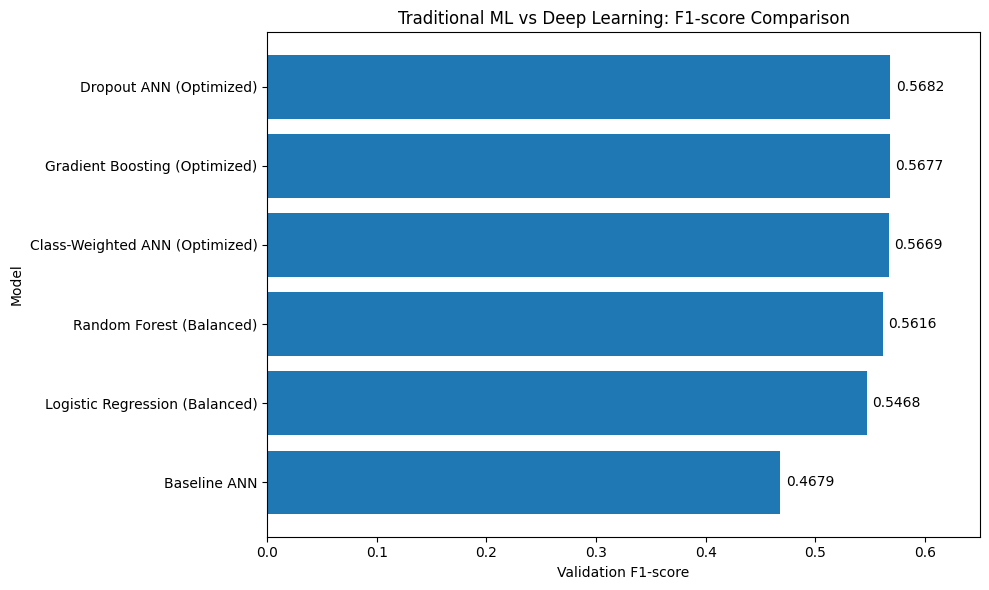

In [26]:

import matplotlib.pyplot as plt

# Use the comparison table already created
plot_data = model_comparison.sort_values("F1-score")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data["Model"],
    plot_data["F1-score"]
)

plt.xlabel("Validation F1-score")
plt.ylabel("Model")
plt.title("Traditional ML vs Deep Learning: F1-score Comparison")
plt.xlim(0, 0.65)

# Display scores beside each bar
for bar in bars:
    plt.text(
        bar.get_width() + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.4f}",
        va="center"
    )

plt.tight_layout()
plt.show()



### Restoring the Selected Gradient Boosting Model

The selected Gradient Boosting classifier is refitted using the previously identified hyperparameters after a Google Colab runtime disconnection.

No additional hyperparameter tuning is performed. The model is trained exclusively on the training dataset, and its previously selected classification threshold of 0.60 is retained for final evaluation.


In [29]:

from sklearn.ensemble import HistGradientBoostingClassifier
import time

# Restore the selected Gradient Boosting configuration
gb_final = HistGradientBoostingClassifier(
    max_iter=100,
    max_depth=6,
    learning_rate=0.1,
    class_weight="balanced",
    random_state=42
)

# Train using the existing preprocessed training data
start_time = time.time()

gb_final.fit(X_train_processed, y_train)

gb_training_time = time.time() - start_time

print("Gradient Boosting model restored successfully!")
print("Training time:",
      round(gb_training_time, 2), "seconds")
print("Model:", gb_final)


Gradient Boosting model restored successfully!
Training time: 18.36 seconds
Model: HistGradientBoostingClassifier(class_weight='balanced', max_depth=6,
                               random_state=42)


In [30]:

import os
import joblib
import json

# Existing Google Drive project folder
save_dir = "/content/drive/MyDrive/BRFSS_Depression_Project"
os.makedirs(save_dir, exist_ok=True)

# Save fitted Gradient Boosting model
joblib.dump(
    gb_final,
    os.path.join(save_dir, "gradient_boosting_final.joblib")
)

# Save previously selected validation threshold
gb_metadata = {
    "model": "Balanced HistGradientBoosting",
    "selected_threshold": 0.60,
    "max_iter": 100,
    "max_depth": 6,
    "learning_rate": 0.1,
    "class_weight": "balanced",
    "random_state": 42
}

with open(
    os.path.join(save_dir, "gradient_boosting_metadata.json"),
    "w"
) as file:
    json.dump(gb_metadata, file, indent=4)

print("Gradient Boosting saved successfully!")
print("Location:", save_dir)


Gradient Boosting saved successfully!
Location: /content/drive/MyDrive/BRFSS_Depression_Project


In [31]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Generate validation probabilities
gb_val_prob = gb_final.predict_proba(
    X_val_processed
)[:, 1]

# Apply previously selected threshold
gb_val_pred = (gb_val_prob >= 0.60).astype(int)

# Calculate validation metrics
gb_validation_results = {
    "Accuracy": accuracy_score(y_val, gb_val_pred),
    "Precision": precision_score(
        y_val, gb_val_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, gb_val_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, gb_val_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, gb_val_prob
    )
}

print("Restored Gradient Boosting Validation Results")
print("-" * 48)

for metric, value in gb_validation_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_val_pred))


Restored Gradient Boosting Validation Results
------------------------------------------------
Accuracy: 0.7934
Precision: 0.5087
Recall: 0.6421
F1-score: 0.5677
ROC-AUC: 0.8168

Confusion Matrix:
[[44890  8942]
 [ 5160  9259]]



## Final Evaluation on the Unseen Test Dataset

The selected Gradient Boosting and class-weighted Dropout ANN models are evaluated on the held-out test dataset.

Both models use the classification threshold of 0.60, previously selected using validation data. The test set is used only for final performance assessment, not for further hyperparameter or threshold optimization.


In [32]:

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Previously selected validation threshold
final_threshold = 0.60

# Gradient Boosting predictions
gb_test_prob = gb_final.predict_proba(
    X_test_processed
)[:, 1]

gb_test_pred = (
    gb_test_prob >= final_threshold
).astype(int)

# Dropout ANN predictions
dropout_test_prob = ann_dropout.predict(
    test_dataset,
    verbose=0
).ravel()

dropout_test_pred = (
    dropout_test_prob >= final_threshold
).astype(int)

# Evaluation function
def evaluate_final_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Consolidate final test results
final_test_results = pd.DataFrame([
    evaluate_final_model(
        "Gradient Boosting",
        y_test,
        gb_test_pred,
        gb_test_prob
    ),
    evaluate_final_model(
        "Dropout ANN",
        y_test_dl,
        dropout_test_pred,
        dropout_test_prob
    )
])

print("FINAL TEST-SET RESULTS")
print("-" * 45)

display(final_test_results.round(4))

print("\nGradient Boosting Confusion Matrix:")
print(confusion_matrix(y_test, gb_test_pred))

print("\nDropout ANN Confusion Matrix:")
print(confusion_matrix(y_test_dl, dropout_test_pred))


FINAL TEST-SET RESULTS
---------------------------------------------


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.7914,0.5050,0.6375,0.5636,0.8158
1,Dropout ANN,0.7846,0.4926,0.6570,0.5630,0.8154



Gradient Boosting Confusion Matrix:
[[44822  9010]
 [ 5227  9192]]

Dropout ANN Confusion Matrix:
[[44074  9758]
 [ 4946  9473]]



### Final Test-Set Performance Comparison

This visualization compares the selected traditional machine learning and deep learning models using accuracy, precision, recall, F1-score, and ROC-AUC on the held-out test dataset.


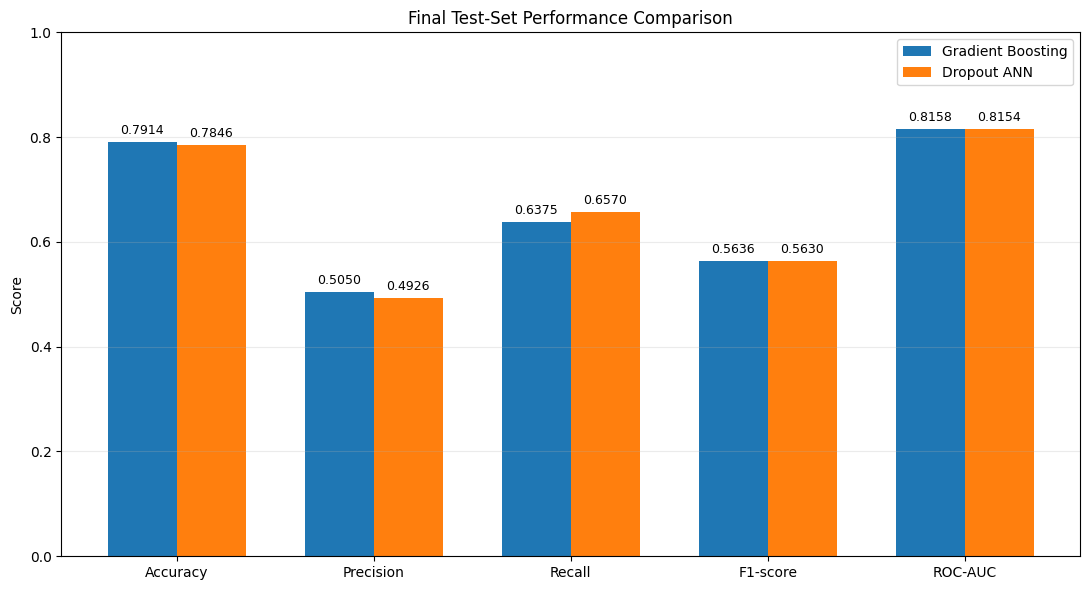

Figure saved to: /content/drive/MyDrive/BRFSS_Depression_Project/final_test_model_comparison.png


In [33]:

import matplotlib.pyplot as plt
import numpy as np
import os

# Prepare comparison data
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

gb_scores = final_test_results.iloc[0][metrics].astype(float).values
ann_scores = final_test_results.iloc[1][metrics].astype(float).values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(
    x - width / 2,
    gb_scores,
    width,
    label="Gradient Boosting"
)

bars2 = plt.bar(
    x + width / 2,
    ann_scores,
    width,
    label="Dropout ANN"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Final Test-Set Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)

# Add metric values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.4f}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

# Save figure to Google Drive
figure_path = os.path.join(
    save_dir,
    "final_test_model_comparison.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)



### Final Test-Set Confusion Matrices

The confusion matrices illustrate the true negatives, false positives, false negatives, and true positives produced by Gradient Boosting and the Dropout ANN on the held-out test dataset.

Both models use the previously selected classification threshold of 0.60.


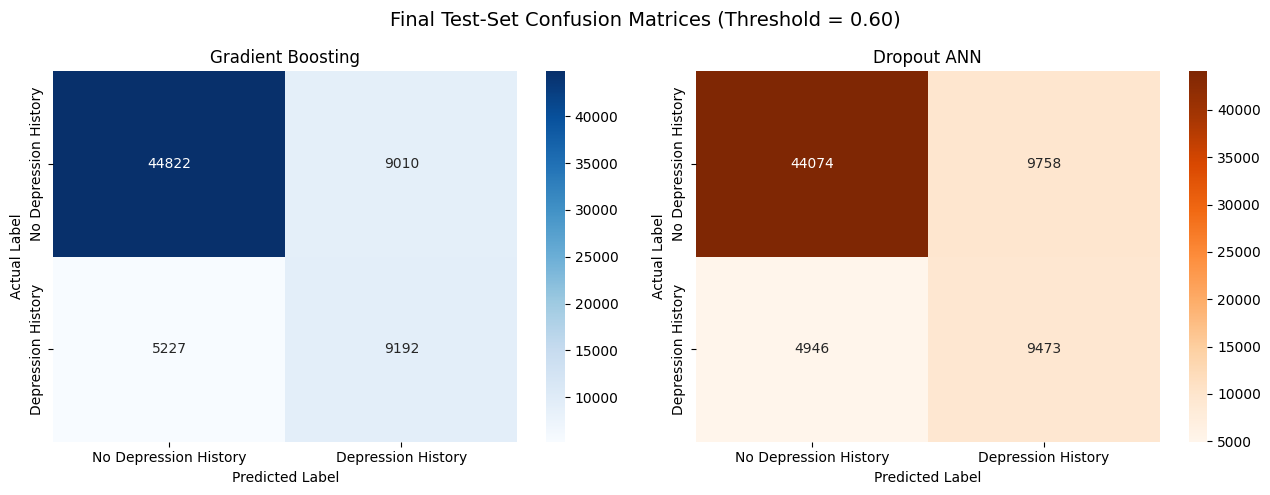

Confusion matrices saved to: /content/drive/MyDrive/BRFSS_Depression_Project/final_test_confusion_matrices.png


In [34]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

# Calculate confusion matrices
cm_gb = confusion_matrix(y_test, gb_test_pred)
cm_ann = confusion_matrix(y_test_dl, dropout_test_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gradient Boosting
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Depression History", "Depression History"],
    yticklabels=["No Depression History", "Depression History"],
    ax=axes[0]
)
axes[0].set_title("Gradient Boosting")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Dropout ANN
sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Depression History", "Depression History"],
    yticklabels=["No Depression History", "Depression History"],
    ax=axes[1]
)
axes[1].set_title("Dropout ANN")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.suptitle(
    "Final Test-Set Confusion Matrices (Threshold = 0.60)",
    fontsize=14
)

plt.tight_layout()

# Save figure
cm_path = os.path.join(
    save_dir,
    "final_test_confusion_matrices.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrices saved to:", cm_path)



###Final Test-Set ROC Curve Comparison

Receiver Operating Characteristic (ROC) curves are used to compare the discrimination performance of Gradient Boosting and the Dropout ANN on the held-out test dataset.

The Area Under the Curve (AUC) summarizes each model's ability to distinguish between respondents who reported a history of depression and those who did not.


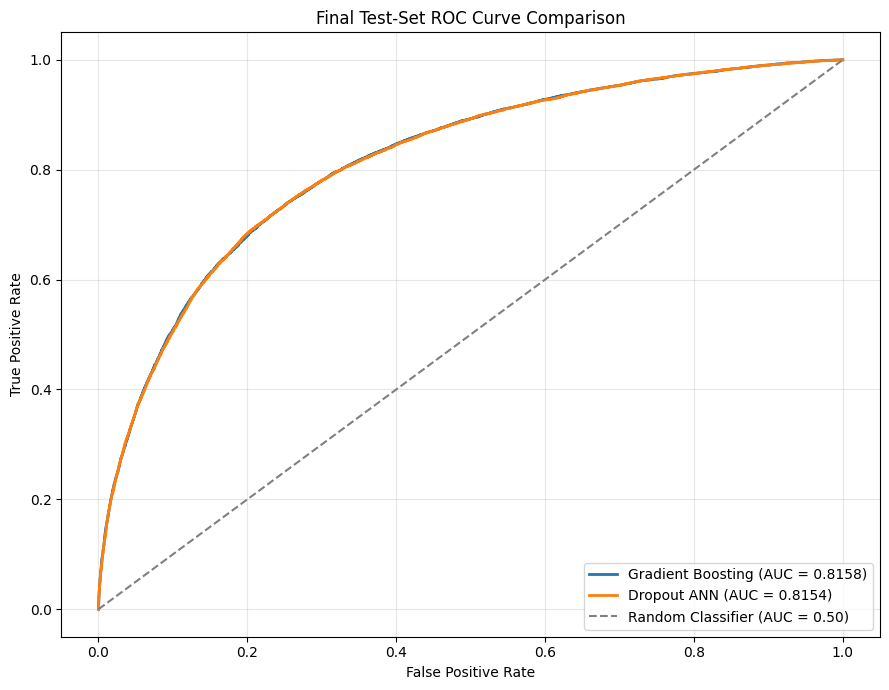

ROC curve saved to: /content/drive/MyDrive/BRFSS_Depression_Project/final_test_roc_curves.png


In [35]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import os

# Calculate ROC curves
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_test_prob)
fpr_ann, tpr_ann, _ = roc_curve(y_test_dl, dropout_test_prob)

# Calculate AUC scores
auc_gb = roc_auc_score(y_test, gb_test_prob)
auc_ann = roc_auc_score(y_test_dl, dropout_test_prob)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_gb, tpr_gb,
    label=f"Gradient Boosting (AUC = {auc_gb:.4f})",
    linewidth=2
)

plt.plot(
    fpr_ann, tpr_ann,
    label=f"Dropout ANN (AUC = {auc_ann:.4f})",
    linewidth=2
)

# Random classifier reference
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Test-Set ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save to Google Drive
roc_path = os.path.join(
    save_dir,
    "final_test_roc_curves.png"
)

plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve saved to:", roc_path)



## Discussion of Final Results

### Comparison of Traditional Machine Learning and Deep Learning

The final evaluation compared a balanced Histogram-Based Gradient Boosting classifier with a class-weighted Artificial Neural Network incorporating dropout regularization. Both models were evaluated on an unseen test dataset containing 68,251 observations, using classification thresholds of 0.60 selected during validation.

Gradient Boosting achieved an accuracy of 0.7914, precision of 0.5050, recall of 0.6375, F1-score of 0.5636, and ROC-AUC of 0.8158. The Dropout ANN achieved an accuracy of 0.7846, precision of 0.4926, recall of 0.6570, F1-score of 0.5630, and ROC-AUC of 0.8154.

Gradient Boosting demonstrated slightly higher accuracy, precision, F1-score, and ROC-AUC, while the Dropout ANN achieved higher recall. The difference in F1-score was only 0.0006, indicating that the models performed very similarly on the held-out test dataset.

The confusion matrices revealed that the Dropout ANN correctly identified 281 more respondents reporting a history of depression, but also generated 748 additional false positives compared with Gradient Boosting.

Overall, these findings suggest that the selected deep learning architecture did not provide a substantial predictive performance advantage over the selected traditional machine learning model on this structured survey dataset.

### Limitations

Several limitations should be considered when interpreting these findings:

1. The target variable, ADDEPEV3, represents respondents' self-reported history of being told by a healthcare professional that they had a depressive disorder. It does not represent a new clinical diagnosis or necessarily indicate current depression.

2. The BRFSS dataset is observational and self-reported, meaning responses may be affected by recall errors, reporting bias, and differences in access to healthcare.

3. The dataset exhibits class imbalance, with approximately 21% positive observations, making metrics such as precision, recall, F1-score, and ROC-AUC particularly important.

4. The analysis did not incorporate BRFSS survey weights or fully account for its complex sampling design. Consequently, the observed class proportions and evaluation results should not be interpreted as nationally representative prevalence estimates.

5. The experiments evaluated selected model architectures and hyperparameter configurations. Their results do not establish that one entire family of algorithms is universally superior.

6. The models identify statistical patterns and associations rather than causal relationships. They are not intended for clinical diagnosis or individual mental health assessment.

### Conclusion

This study compared traditional machine learning and deep learning approaches for predicting self-reported depression history using the 2024 CDC BRFSS dataset.

Both approaches demonstrated useful discrimination, achieving test ROC-AUC scores of approximately 0.816. Gradient Boosting achieved marginally better overall classification metrics, whereas the Dropout ANN offered slightly higher sensitivity to positive cases.

The findings indicate that traditional machine learning remains a competitive approach for structured public health survey data, and that greater model complexity does not necessarily produce better predictive performance.



## Project Artifacts and Submission Preparation

This section verifies the saved machine learning models, preprocessing pipeline, model metadata, and evaluation visualizations required for reproducibility and final project submission.


In [36]:

import os

save_dir = "/content/drive/MyDrive/BRFSS_Depression_Project"

required_files = [
    "ann_weighted.keras",
    "ann_dropout.keras",
    "gradient_boosting_final.joblib",
    "preprocessor.joblib",
    "ann_dropout_metadata.json",
    "gradient_boosting_metadata.json",
    "final_test_model_comparison.png",
    "final_test_confusion_matrices.png",
    "final_test_roc_curves.png"
]

print("PROJECT ARTIFACT VERIFICATION")
print("=" * 55)

missing_files = []

for filename in required_files:
    filepath = os.path.join(save_dir, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)
        print(f"FOUND: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {filename}")
        missing_files.append(filename)

print("\n" + "=" * 55)

if not missing_files:
    print("SUCCESS: All required project artifacts are saved!")
else:
    print(f"WARNING: {len(missing_files)} files are missing.")
    print("Missing files:", missing_files)


PROJECT ARTIFACT VERIFICATION
FOUND: ann_weighted.keras (0.09 MB)
FOUND: ann_dropout.keras (0.10 MB)
FOUND: gradient_boosting_final.joblib (0.36 MB)
FOUND: preprocessor.joblib (0.00 MB)
FOUND: ann_dropout_metadata.json (0.00 MB)
FOUND: gradient_boosting_metadata.json (0.00 MB)
FOUND: final_test_model_comparison.png (0.13 MB)
FOUND: final_test_confusion_matrices.png (0.20 MB)
FOUND: final_test_roc_curves.png (0.20 MB)

SUCCESS: All required project artifacts are saved!


In [39]:


import shutil
import os

source = "/content/LLCP2024XPT.zip"

destination = (
    "/content/drive/MyDrive/"
    "BRFSS_Depression_Project/LLCP2024XPT.zip"
)

# Copy the original dataset to Google Drive
shutil.copy2(source, destination)

# Verify the saved file
if os.path.isfile(destination):
    size_mb = os.path.getsize(destination) / (1024 ** 2)

    print("Dataset successfully saved to Google Drive!")
    print("File:", destination)
    print(f"Size: {size_mb:.2f} MB")
else:
    print("Dataset copy failed.")




Dataset successfully saved to Google Drive!
File: /content/drive/MyDrive/BRFSS_Depression_Project/LLCP2024XPT.zip
Size: 79.16 MB
